<a href="https://colab.research.google.com/github/Rajdas129/Consulting-and-advisory-work/blob/main/AmberFrost_FoodPlant_Causal_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AmberFrost Foods: Food Plant Experiment & Causal Analysis

## Business Problem
AmberFrost Foods, a fictional frozen food manufacturer in Jaipur,
wants to determine whether its operational improvements have
genuinely improved production performance.

The analysis covers two initiatives:
1. SmartBlanch: A prospective A/B experiment.
2. Process 2.0: A retrospective historical intervention.

## Project Objectives
- Clean and validate production datasets.
- Design an experiment using statistical power analysis.
- Evaluate treatment effects using A/B testing.
- Assess historical impact using Difference-in-Differences.
- Identify heterogeneous effects across operational segments.
- Apply CUPED or regression adjustment.
- Deliver actionable business recommendations.

## Analytical Tools
- Python
- Google Colab
- Pandas and NumPy
- SciPy and Statsmodels
- Matplotlib and Seaborn

## Statistical Standards
- Significance level: 5%
- Confidence level: 95%
- Statistical power: 80% (initial design target)

In [ ]:
# 01. ENVIRONMENT SETUP

import os
import zipfile
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from IPython.display import display

warnings.filterwarnings("ignore")

# Display configuration
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment successfully configured.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Ready for data loading.")

Environment successfully configured.
Pandas version: 2.2.3
NumPy version: 2.4.6
Ready for data loading.


In [ ]:
# 02. DATASET UPLOAD AND EXTRACTION

import os
import zipfile
import io

from google.colab import files

# Upload ZIP archive
uploaded = files.upload()

# Identify ZIP file
zip_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".zip")
]

if len(zip_files) != 1:
    raise ValueError("Upload exactly one ZIP archive.")

zip_name = zip_files[0]

# Define extraction directory
DATA_DIR = "/content/amberfrost_data"

os.makedirs(DATA_DIR, exist_ok=True)

# Extract directly from uploaded bytes
zip_bytes = io.BytesIO(uploaded[zip_name])

with zipfile.ZipFile(zip_bytes, "r") as zip_ref:

    # Validate archive
    bad_file = zip_ref.testzip()

    if bad_file:
        raise ValueError(f"Corrupted file detected: {bad_file}")

    # Extract archive
    zip_ref.extractall(DATA_DIR)

print("Dataset extracted successfully!")
print("Extraction directory:", DATA_DIR)

# Display extracted files
print("\nEXTRACTED FILES")
print("-" * 50)

for filename in sorted(os.listdir(DATA_DIR)):

    file_path = os.path.join(DATA_DIR, filename)

    if os.path.isfile(file_path):

        print(
            f"{filename:<40} "
            f"{os.path.getsize(file_path) / 1024:.2f} KB"
        )

Saving AmberFrost_dataset(project).zip to AmberFrost_dataset(project).zip
Dataset extracted successfully!
Extraction directory: /content/amberfrost_data

EXTRACTED FILES
--------------------------------------------------
01_batches.csv                           2483.29 KB
02_raw_material_lots.csv                 6319.14 KB
03_machine_logs.csv                      5954.06 KB
04_quality_tests.csv                     6148.72 KB
05_control_region_kota_daily.csv         116.08 KB
06_experiment_smartblanch.csv            139.71 KB
README.md                                4.35 KB


In [ ]:
# 03. DATA LOADING


csv_files = {}

for filename in sorted(os.listdir(DATA_DIR)):

    if filename.lower().endswith(".csv"):

        file_path = os.path.join(DATA_DIR, filename)

        csv_files[filename] = pd.read_csv(file_path)

print("Successfully loaded datasets:", len(csv_files))

for filename, df in csv_files.items():
    print(f"{filename}: {df.shape}")

Successfully loaded datasets: 6
01_batches.csv: (24691, 14)
02_raw_material_lots.csv: (74631, 10)
03_machine_logs.csv: (98764, 9)
04_quality_tests.csv: (98764, 7)
05_control_region_kota_daily.csv: (1895, 9)
06_experiment_smartblanch.csv: (1260, 17)


In [ ]:
# 04. DATASET INVENTORY

inventory = []

for filename, df in csv_files.items():

    inventory.append({
        "Dataset": filename,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / 1024**2, 2
        )
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

print("Total records:", inventory_df["Rows"].sum())

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Memory (MB)
0,01_batches.csv,24691,14,1549,0,14.910
1,02_raw_material_lots.csv,74631,10,48888,0,30.700
2,03_machine_logs.csv,98764,9,0,0,25.500
3,04_quality_tests.csv,98764,7,0,0,29.650
4,05_control_region_kota_daily.csv,1895,9,0,0,0.400
5,06_experiment_smartblanch.csv,1260,17,0,0,0.510


Total records: 300005


In [ ]:
# 05. COLUMN STRUCTURE

for filename, df in csv_files.items():

    print("\n" + "=" * 70)
    print("DATASET:", filename)
    print("=" * 70)

    display(pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Values": df.isna().sum().values,
        "Missing (%)": (
            df.isna().mean().values * 100
        ).round(2)
    }))

    display(df.head(3))


DATASET: 01_batches.csv


,Column,Data Type,Missing Values,Missing (%)
0,batch_id,object,0,0.000
1,plant,object,0,0.000
2,line_id,object,0,0.000
3,batch_date,object,0,0.000
4,shift,object,0,0.000
5,start_time,object,0,0.000
6,product,object,0,0.000
7,operator_id,object,0,0.000
8,raw_input_weight,float64,0,0.000
9,raw_input_unit,object,497,2.010


,batch_id,plant,line_id,batch_date,shift,start_time,product,operator_id,raw_input_weight,raw_input_unit,finished_output_weight,finished_output_unit,waste_weight,waste_unit
0,JPR-000001,Jaipur,L1,2025-01-01,Morning,2025-01-01 06:17,Aloo Tikki,OP029,1337.400,kg,1163.800,kg,128.300,kg
1,JPR-000002,Jaipur,L2,2025-01-01,Morning,2025-01-01 06:17,Green Peas,OP007,2319.600,kg,2184.400,kg,79.800,kg
2,JPR-000003,Jaipur,L3,2025-01-01,Morning,2025-01-01 06:18,Paneer Tikka,OP025,1861300.000,g,1552.700,kg,218.600,kg



DATASET: 02_raw_material_lots.csv


,Column,Data Type,Missing Values,Missing (%)
0,lot_id,object,0,0.000
1,batch_id,object,0,0.000
2,material,object,0,0.000
3,supplier_name,object,0,0.000
4,received_date,object,0,0.000
5,quantity,float64,0,0.000
6,quantity_unit,object,1492,2.000
7,moisture_pct,float64,47396,63.510
8,inspection_shift,object,0,0.000
9,cost_per_kg_inr,float64,0,0.000


,lot_id,batch_id,material,supplier_name,received_date,quantity,quantity_unit,moisture_pct,inspection_shift,cost_per_kg_inr
0,LOT-0000001,JPR-000001,Potato,MARUDHAR FARMS,2024-12-30,1043.200,kg,78.400,Morning,20.460
1,LOT-0000002,JPR-000001,Flour/Binder,Rajputana Mills,2024-12-31,160.500,kg,NaN,Morning,30.380
2,LOT-0000003,JPR-000001,Oil,Thar Spices & Oils,2024-12-31,66.900,kg,NaN,Morning,146.010


... (8 outputs left out)

,date,region,line_id,batches_run,raw_input_kg,finished_output_kg,waste_kg,units_tested,units_rejected
0,2025-01-01,Kota (control),L1,9,14908.900,12912.500,1422.400,1658,37
1,2025-01-01,Kota (control),L2,12,27111.000,23688.200,2241.500,2269,55
2,2025-01-01,Kota (control),L3,12,17489.400,14628.600,2160.100,2345,81



DATASET: 06_experiment_smartblanch.csv


,Column,Data Type,Missing Values,Missing (%)
0,batch_id,object,0,0.000
1,batch_date,object,0,0.000
2,line_id,object,0,0.000
3,shift,object,0,0.000
4,product,object,0,0.000
5,variant,object,0,0.000
6,raw_input_kg,float64,0,0.000
7,lot_pretest_yield_pct,float64,0,0.000
8,raw_moisture_pct,float64,0,0.000
9,pre_period_line_product_yield_pct,float64,0,0.000


,batch_id,batch_date,line_id,shift,product,variant,raw_input_kg,lot_pretest_yield_pct,raw_moisture_pct,pre_period_line_product_yield_pct,yield_pct,wastage_pct,units_tested,units_rejected,rejection_rate_pct,energy_kwh_per_kg,cycle_time_min
0,EXP-00001,2026-10-01,L1,Morning,Aloo Tikki,treatment,1144.500,87.190,79.700,90.222,88.007,8.218,153,3,1.961,0.291,103.000
1,EXP-00002,2026-10-01,L3,Morning,Paneer Tikka,treatment,1498.500,85.190,76.700,85.861,88.602,6.186,224,8,3.571,0.279,103.900
2,EXP-00003,2026-10-01,L2,Morning,Green Peas,control,1809.400,92.970,78.100,94.143,93.009,2.028,198,4,2.020,0.285,98.600


In [ ]:
# 06. PROJECT DATA DICTIONARY

readme_path = os.path.join(DATA_DIR, "README.md")

with open(readme_path, "r", encoding="utf-8") as file:

    readme_content = file.read()

print(readme_content)

# Amber Frost Foods — Experiment & Causal Analysis Dataset
**Fully synthetic. Fictional company.** Generated by `generate_food_data.py` (seed 2026, reproducible).

## Business context
- **Company:** Amber Frost Foods Pvt Ltd, frozen foods, Jaipur plant, 3 lines (L1, L2, L3).
- **Products:** Aloo Tikki, Veg Momos, Mixed Veg, Green Peas, Paneer Tikka.
- **Shifts:** Morning (06–14), Evening (14–22), Night (22–06).
- **Last quarter's change:** "Process 2.0 SOP" launched at Jaipur on **2026-07-01**, all lines. Management claims yield improved. No experiment was run.
- **Control region:** Kota plant. Same products, same line setup, did NOT adopt Process 2.0.
- **New initiative tested:** "SmartBlanch" auto-tuned blanching. Batch-level randomised A/B test, **2026-10-01 to 2026-11-01**, Jaipur. Planned split 50/50, block-randomised within date × line × shift.

## Files
| # | File | Rows | Grain | Period |
|---|---|---|---|---|
| 01 | batches.csv | 24,691 | 1 production batch | 2025-01-01 → 2026

In [ ]:

# DATASET INVENTORY

inventory = []

for filename, df in csv_files.items():

    inventory.append({
        "Dataset": filename,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / 1024**2, 2
        )
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

print("\nTotal datasets:", len(csv_files))
print("Total records:", f"{inventory_df['Rows'].sum():,}")

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Memory (MB)
0,01_batches.csv,24691,14,1549,0,14.910
1,02_raw_material_lots.csv,74631,10,48888,0,30.700
2,03_machine_logs.csv,98764,9,0,0,25.500
3,04_quality_tests.csv,98764,7,0,0,29.650
4,05_control_region_kota_daily.csv,1895,9,0,0,0.400
5,06_experiment_smartblanch.csv,1260,17,0,0,0.510



Total datasets: 6
Total records: 300,005


In [ ]:

# PRIMARY KEY VALIDATION


primary_keys = {
    "01_batches.csv": "batch_id",
    "02_raw_material_lots.csv": "lot_id",
    "03_machine_logs.csv": "log_id",
    "04_quality_tests.csv": "test_id",
    "05_control_region_kota_daily.csv": None,
    "06_experiment_smartblanch.csv": "batch_id"
}

for filename, key in primary_keys.items():

    df = csv_files[filename]

    print("\n" + "=" * 60)
    print("DATASET:", filename)

    if key is None:
        print("No single-column primary key specified.")
        continue

    if key not in df.columns:
        print("ERROR: Expected key not found:", key)
        continue

    print("Primary key:", key)
    print("Total records:", len(df))
    print("Unique identifiers:", df[key].nunique())
    print("Missing identifiers:", df[key].isna().sum())
    print("Duplicate identifiers:", df[key].duplicated().sum())


DATASET: 01_batches.csv
Primary key: batch_id
Total records: 24691
Unique identifiers: 24691
Missing identifiers: 0
Duplicate identifiers: 0

DATASET: 02_raw_material_lots.csv
Primary key: lot_id
Total records: 74631
Unique identifiers: 74631
Missing identifiers: 0
Duplicate identifiers: 0

DATASET: 03_machine_logs.csv
Primary key: log_id
Total records: 98764
Unique identifiers: 98764
Missing identifiers: 0
Duplicate identifiers: 0

DATASET: 04_quality_tests.csv
Primary key: test_id
Total records: 98764
Unique identifiers: 98764
Missing identifiers: 0
Duplicate identifiers: 0

DATASET: 05_control_region_kota_daily.csv
No single-column primary key specified.

DATASET: 06_experiment_smartblanch.csv
Primary key: batch_id
Total records: 1260
Unique identifiers: 1260
Missing identifiers: 0
Duplicate identifiers: 0


In [ ]:

# FOREIGN KEY AND RELATIONSHIP VALIDATION


batches = csv_files["01_batches.csv"]

batch_ids = set(batches["batch_id"])

child_datasets = [
    "02_raw_material_lots.csv",
    "03_machine_logs.csv",
    "04_quality_tests.csv",
    "06_experiment_smartblanch.csv"
]

for filename in child_datasets:

    df = csv_files[filename]

    print("\n" + "=" * 65)
    print("DATASET:", filename)

    missing_fk = df["batch_id"].isna().sum()

    orphan_fk = (
        ~df["batch_id"].isin(batch_ids)
    ).sum()

    print("Total records:", len(df))
    print("Missing batch_id:", missing_fk)
    print("Orphan batch_id:", orphan_fk)

    if filename != "06_experiment_smartblanch.csv":

        relationship = df.groupby("batch_id").size()

        print("Unique batches referenced:", relationship.size)
        print("Maximum records per batch:", relationship.max())
        print("Average records per batch:",
              round(relationship.mean(), 2))

    else:

        print("Unique experimental batches:",
              df["batch_id"].nunique())

# Validate Kota's proposed composite key
kota = csv_files["05_control_region_kota_daily.csv"]

print("\n" + "=" * 65)
print("KOTA CONTROL DATASET")

print("Missing dates:", kota["date"].isna().sum())
print("Missing line IDs:", kota["line_id"].isna().sum())

print("Duplicate date-line combinations:",
      kota.duplicated(subset=["date", "line_id"]).sum())

print("Unique dates:", kota["date"].nunique())
print("Unique production lines:", kota["line_id"].nunique())


DATASET: 02_raw_material_lots.csv
Total records: 74631
Missing batch_id: 0
Orphan batch_id: 0
Unique batches referenced: 24691
Maximum records per batch: 4
Average records per batch: 3.02

DATASET: 03_machine_logs.csv
Total records: 98764
Missing batch_id: 0
Orphan batch_id: 0
Unique batches referenced: 24691
Maximum records per batch: 4
Average records per batch: 4.0

DATASET: 04_quality_tests.csv
Total records: 98764
Missing batch_id: 0
Orphan batch_id: 0
Unique batches referenced: 24691
Maximum records per batch: 4
Average records per batch: 4.0

DATASET: 06_experiment_smartblanch.csv
Total records: 1260
Missing batch_id: 0
Orphan batch_id: 1260
Unique experimental batches: 1260

KOTA CONTROL DATASET
Missing dates: 0
Missing line IDs: 0
Duplicate date-line combinations: 0
Unique dates: 638
Unique production lines: 3


In [ ]:

# DATE COVERAGE VALIDATION


date_columns = {
    "01_batches.csv": "batch_date",
    "05_control_region_kota_daily.csv": "date",
    "06_experiment_smartblanch.csv": "batch_date"
}

for filename, date_col in date_columns.items():

    df = csv_files[filename]

    print("\n" + "=" * 65)
    print("DATASET:", filename)

    if date_col not in df.columns:
        print("Date column not found:", date_col)
        print("Available columns:", df.columns.tolist())
        continue

    dates = pd.to_datetime(df[date_col], errors="coerce")

    print("Date column:", date_col)
    print("Minimum date:", dates.min())
    print("Maximum date:", dates.max())
    print("Missing/invalid dates:", dates.isna().sum())
    print("Unique dates:", dates.nunique())


DATASET: 01_batches.csv
Date column: batch_date
Minimum date: 2025-01-01 00:00:00
Maximum date: 2026-09-30 00:00:00
Missing/invalid dates: 0
Unique dates: 638

DATASET: 05_control_region_kota_daily.csv
Date column: date
Minimum date: 2025-01-01 00:00:00
Maximum date: 2026-09-30 00:00:00
Missing/invalid dates: 0
Unique dates: 638

DATASET: 06_experiment_smartblanch.csv
Date column: batch_date
Minimum date: 2026-10-01 00:00:00
Maximum date: 2026-11-01 00:00:00
Missing/invalid dates: 0
Unique dates: 32


In [ ]:

# HISTORICAL PRODUCTION: COLUMN AND DATA-TYPE AUDIT


batches = csv_files["01_batches.csv"]

print("DATASET SHAPE:", batches.shape)

print("\nCOLUMN NAMES AND DATA TYPES:")
display(pd.DataFrame({
    "Column": batches.columns,
    "Data Type": batches.dtypes.astype(str).values,
    "Missing Values": batches.isna().sum().values,
    "Missing (%)": (batches.isna().mean().values * 100).round(2)
}))

print("\nSAMPLE RECORDS:")
display(batches.head(5))

print("\nUNIT DISTRIBUTIONS:")
for col in ["raw_input_unit", "finished_output_unit", "waste_unit"]:
    if col in batches.columns:
        print(f"\n{col}:")
        display(batches[col].value_counts(dropna=False))

DATASET SHAPE: (24691, 14)

COLUMN NAMES AND DATA TYPES:


,Column,Data Type,Missing Values,Missing (%)
0,batch_id,object,0,0.000
1,plant,object,0,0.000
2,line_id,object,0,0.000
3,batch_date,object,0,0.000
4,shift,object,0,0.000
5,start_time,object,0,0.000
6,product,object,0,0.000
7,operator_id,object,0,0.000
8,raw_input_weight,float64,0,0.000
9,raw_input_unit,object,497,2.010



SAMPLE RECORDS:


,batch_id,plant,line_id,batch_date,shift,start_time,product,operator_id,raw_input_weight,raw_input_unit,finished_output_weight,finished_output_unit,waste_weight,waste_unit
0,JPR-000001,Jaipur,L1,2025-01-01,Morning,2025-01-01 06:17,Aloo Tikki,OP029,1337.400,kg,1163.800,kg,128.300,kg
1,JPR-000002,Jaipur,L2,2025-01-01,Morning,2025-01-01 06:17,Green Peas,OP007,2319.600,kg,2184.400,kg,79.800,kg
2,JPR-000003,Jaipur,L3,2025-01-01,Morning,2025-01-01 06:18,Paneer Tikka,OP025,1861300.000,g,1552.700,kg,218.600,kg
3,JPR-000004,Jaipur,L1,2025-01-01,Morning,2025-01-01 07:58,Paneer Tikka,OP016,1268.000,kg,1125.400,kg,69.900,kg
4,JPR-000005,Jaipur,L3,2025-01-01,Morning,2025-01-01 08:00,Veg Momos,OP015,1234.200,kg,978.900,kg,214.100,kg



UNIT DISTRIBUTIONS:

raw_input_unit:


,count
raw_input_unit,
kg,20930
gm,784
grams,745
g,731
NaN,497
KG,335
kgs,335
Kg,334



finished_output_unit:


,count
finished_output_unit,
kg,20911
grams,760
g,738
gm,717
NaN,529
KG,357
Kg,343
kgs,336



waste_unit:


,count
waste_unit,
kg,20907
gm,790
g,778
grams,712
NaN,523
KG,344
Kg,335
kgs,302


In [ ]:
# WEIGHT STANDARDISATION: ALL VALUES TO KG

unit_columns = {
    "raw_input_weight": "raw_input_unit",
    "finished_output_weight": "finished_output_unit",
    "waste_weight": "waste_unit"
}

unit_map = {
    "kg": "kg",
    "kgs": "kg",
    "g": "g",
    "gm": "g",
    "grams": "g"
}

for weight_col, unit_col in unit_columns.items():

    units = batches[unit_col].astype("string").str.strip().str.lower()

    # README rule: missing unit means grams
    units = units.fillna("g").map(unit_map)

    if units.isna().any():
        unknown = batches.loc[units.isna(), unit_col].unique()
        raise ValueError(f"Unexpected units in {unit_col}: {unknown}")

    batches[f"{weight_col}_kg"] = np.where(
        units == "g",
        batches[weight_col] / 1000,
        batches[weight_col]
    )

print("STANDARDISATION COMPLETE")

print("\nSTANDARDISED WEIGHT SUMMARY (KG):")
display(
    batches[
        ["raw_input_weight_kg",
         "finished_output_weight_kg",
         "waste_weight_kg"]
    ].describe().round(2)
)

print("\nCHECK: ORIGINAL AND STANDARDISED SAMPLE")
display(
    batches[
        ["raw_input_weight", "raw_input_unit", "raw_input_weight_kg",
         "finished_output_weight", "finished_output_unit", "finished_output_weight_kg",
         "waste_weight", "waste_unit", "waste_weight_kg"]
    ].head(8)
)

STANDARDISATION COMPLETE

STANDARDISED WEIGHT SUMMARY (KG):


,raw_input_weight_kg,finished_output_weight_kg,waste_weight_kg
count,24691.000,24691.000,24691.000
mean,1698.380,1475.860,154.160
std,468.960,438.730,77.480
min,900.000,686.300,1.900
25%,1321.600,1136.800,97.850
50%,1668.700,1436.500,145.000
75%,2026.150,1748.700,201.300
max,2859.800,2793.800,478.000



CHECK: ORIGINAL AND STANDARDISED SAMPLE


,raw_input_weight,raw_input_unit,raw_input_weight_kg,finished_output_weight,finished_output_unit,finished_output_weight_kg,waste_weight,waste_unit,waste_weight_kg
0,1337.400,kg,1337.400,1163.800,kg,1163.800,128.300,kg,128.300
1,2319.600,kg,2319.600,2184.400,kg,2184.400,79.800,kg,79.800
2,1861300.000,g,1861.300,1552.700,kg,1552.700,218.600,kg,218.600
3,1268.000,kg,1268.000,1125.400,kg,1125.400,69.900,kg,69.900
4,1234.200,kg,1234.200,978.900,kg,978.900,214.100,kg,214.100
5,2635.300,kg,2635.300,2522.000,kg,2522.000,5.300,kg,5.300
6,2128.100,kg,2128.100,1893.100,kg,1893.100,152.700,kg,152.700
7,1559.500,kg,1559.500,1366.200,kg,1366.200,121.600,kg,121.600


In [ ]:
 # PHYSICAL CONSISTENCY CHECK

raw = batches["raw_input_weight_kg"]
output = batches["finished_output_weight_kg"]
waste = batches["waste_weight_kg"]

checks = {
    "Zero or negative raw input": (raw <= 0).sum(),
    "Zero or negative finished output": (output <= 0).sum(),
    "Negative waste": (waste < 0).sum(),
    "Output exceeds raw input": (output > raw).sum(),
    "Output + waste exceeds raw input": ((output + waste) > raw).sum(),
    "Output + waste equals raw input": ((output + waste) == raw).sum()
}

print("PHYSICAL CONSISTENCY CHECKS:")
display(pd.DataFrame(
    [{"Check": k, "Records": v, "Percentage": round(v / len(batches) * 100, 2)}
     for k, v in checks.items()]
))

# Calculate unaccounted process loss
batches["unaccounted_loss_kg"] = raw - output - waste
batches["unaccounted_loss_pct"] = (
    batches["unaccounted_loss_kg"] / raw * 100
)

print("\nUNACCOUNTED LOSS PERCENTAGE:")
display(batches["unaccounted_loss_pct"].describe().round(2))

print("\nRECORDS WITH OUTPUT + WASTE EXCEEDING INPUT:")
display(
    batches.loc[
        (output + waste) > raw,
        ["batch_id", "batch_date", "line_id", "product",
         "raw_input_weight_kg", "finished_output_weight_kg",
         "waste_weight_kg"]
    ].head(10)
)

PHYSICAL CONSISTENCY CHECKS:


,Check,Records,Percentage
0,Zero or negative raw input,0,0.000
1,Zero or negative finished output,0,0.000
2,Negative waste,0,0.000
3,Output exceeds raw input,0,0.000
4,Output + waste exceeds raw input,0,0.000
5,Output + waste equals raw input,0,0.000



UNACCOUNTED LOSS PERCENTAGE:


,unaccounted_loss_pct
count,24691.000
mean,4.040
std,0.900
min,1.000
25%,3.420
50%,4.040
75%,4.680
max,7.280



RECORDS WITH OUTPUT + WASTE EXCEEDING INPUT:


,batch_id,batch_date,line_id,product,raw_input_weight_kg,finished_output_weight_kg,waste_weight_kg


In [ ]:
# BATCH-LEVEL OPERATIONAL METRICS

batches["yield_pct"] = (
    batches["finished_output_weight_kg"]
    / batches["raw_input_weight_kg"] * 100
)

batches["wastage_pct"] = (
    batches["waste_weight_kg"]
    / batches["raw_input_weight_kg"] * 100
)

print("BATCH-LEVEL METRIC SUMMARY:")
display(
    batches[["yield_pct", "wastage_pct", "unaccounted_loss_pct"]]
    .describe()
    .round(2)
)

print("\nOVERALL PRODUCTION METRICS:")
print("Total batches:", f"{len(batches):,}")
print("Total raw input (tonnes):",
      round(batches["raw_input_weight_kg"].sum() / 1000, 2))
print("Total finished output (tonnes):",
      round(batches["finished_output_weight_kg"].sum() / 1000, 2))
print("Total waste (tonnes):",
      round(batches["waste_weight_kg"].sum() / 1000, 2))
print("Average batch yield (%):",
      round(batches["yield_pct"].mean(), 2))
print("Average batch wastage (%):",
      round(batches["wastage_pct"].mean(), 2))

BATCH-LEVEL METRIC SUMMARY:


,yield_pct,wastage_pct,unaccounted_loss_pct
count,24691.000,24691.000,24691.000
mean,86.550,9.410,4.040
std,4.500,4.470,0.900
min,71.510,0.200,1.000
25%,83.230,6.110,3.420
50%,86.630,9.080,4.040
75%,89.860,12.550,4.680
max,98.500,25.200,7.280



OVERALL PRODUCTION METRICS:
Total batches: 24,691
Total raw input (tonnes): 41934.63
Total finished output (tonnes): 36440.55
Total waste (tonnes): 3806.27
Average batch yield (%): 86.55
Average batch wastage (%): 9.41


In [ ]:

# PROCESS 2.0: PRE/POST PERIOD COVERAGE


batches["batch_date"] = pd.to_datetime(batches["batch_date"])

batches["period"] = np.where(
    batches["batch_date"] < "2026-07-01",
    "Pre-Process 2.0",
    "Post-Process 2.0"
)

print("JAIPUR BATCH COVERAGE:")
display(
    batches.groupby("period").agg(
        batches=("batch_id", "count"),
        first_date=("batch_date", "min"),
        last_date=("batch_date", "max"),
        lines=("line_id", "nunique"),
        products=("product", "nunique")
    ).reset_index()
)

kota = csv_files["05_control_region_kota_daily.csv"].copy()
kota["date"] = pd.to_datetime(kota["date"])

kota["period"] = np.where(
    kota["date"] < "2026-07-01",
    "Pre-Process 2.0",
    "Post-Process 2.0"
)

print("\nKOTA DAILY COVERAGE:")
display(
    kota.groupby("period").agg(
        line_days=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        lines=("line_id", "nunique")
    ).reset_index()
)

JAIPUR BATCH COVERAGE:


,period,batches,first_date,last_date,lines,products
0,Post-Process 2.0,3491,2026-07-01,2026-09-30,3,5
1,Pre-Process 2.0,21200,2025-01-01,2026-06-30,3,5



KOTA DAILY COVERAGE:


,period,line_days,first_date,last_date,lines
0,Post-Process 2.0,271,2026-07-01,2026-09-30,3
1,Pre-Process 2.0,1624,2025-01-01,2026-06-30,3


In [ ]:
# KOTA CONTROL DATA: STRUCTURE AUDIT

print("DATASET SHAPE:", kota.shape)

print("\nCOLUMNS, DATA TYPES AND MISSING VALUES:")
display(pd.DataFrame({
    "Column": kota.columns,
    "Data Type": kota.dtypes.astype(str).values,
    "Missing Values": kota.isna().sum().values
}))

print("\nSAMPLE RECORDS:")
display(kota.head(5))

print("\nNUMERIC SUMMARY:")
display(kota.describe().round(2))

DATASET SHAPE: (1895, 10)

COLUMNS, DATA TYPES AND MISSING VALUES:


,Column,Data Type,Missing Values
0,date,datetime64[ns],0
1,region,object,0
2,line_id,object,0
3,batches_run,int64,0
4,raw_input_kg,float64,0
5,finished_output_kg,float64,0
6,waste_kg,float64,0
7,units_tested,int64,0
8,units_rejected,int64,0
9,period,object,0



SAMPLE RECORDS:


,date,region,line_id,batches_run,raw_input_kg,finished_output_kg,waste_kg,units_tested,units_rejected,period
0,2025-01-01,Kota (control),L1,9,14908.900,12912.500,1422.400,1658,37,Pre-Process 2.0
1,2025-01-01,Kota (control),L2,12,27111.000,23688.200,2241.500,2269,55,Pre-Process 2.0
2,2025-01-01,Kota (control),L3,12,17489.400,14628.600,2160.100,2345,81,Pre-Process 2.0
3,2025-01-02,Kota (control),L1,15,21989.600,18155.500,2987.900,3241,100,Pre-Process 2.0
4,2025-01-02,Kota (control),L2,7,13356.900,12175.400,658.400,1454,36,Pre-Process 2.0



NUMERIC SUMMARY:


,date,batches_run,raw_input_kg,finished_output_kg,waste_kg,units_tested,units_rejected
count,1895,1895.000,1895.000,1895.000,1895.000,1895.000,1895.000
mean,2025-11-15 02:41:05.857519872,12.950,22060.570,18930.510,2241.630,2644.440,75.290
min,2025-01-01 00:00:00,1.000,930.200,762.100,138.600,157.000,5.000
25%,2025-06-09 00:00:00,10.000,16370.650,13808.450,1590.250,2053.000,53.000
50%,2025-11-15 00:00:00,13.000,21999.700,18719.200,2188.800,2683.000,72.000
75%,2026-04-23 00:00:00,16.000,27693.900,23799.650,2838.650,3263.500,95.000
max,2026-09-30 00:00:00,27.000,51790.500,46413.400,5726.600,5545.000,186.000
std,NaN,4.470,8252.300,7365.140,933.570,922.060,32.540


In [ ]:

# JAIPUR: DAILY × LINE AGGREGATION


quality = csv_files["04_quality_tests.csv"]

# Aggregate quality tests to one row per batch
quality_batch = quality.groupby("batch_id").agg(
    units_tested=("units_tested", "sum"),
    units_rejected=("units_rejected", "sum")
).reset_index()

# Join quality totals to production batches
jaipur = batches.merge(
    quality_batch,
    on="batch_id",
    how="left",
    validate="one_to_one"
)

# Aggregate production and quality totals by date and line
jaipur_daily = jaipur.groupby(
    ["batch_date", "line_id"]
).agg(
    batches_run=("batch_id", "count"),
    raw_input_kg=("raw_input_weight_kg", "sum"),
    finished_output_kg=("finished_output_weight_kg", "sum"),
    waste_kg=("waste_weight_kg", "sum"),
    units_tested=("units_tested", "sum"),
    units_rejected=("units_rejected", "sum")
).reset_index()

# Calculate rates from aggregated totals
jaipur_daily["yield_pct"] = (
    jaipur_daily["finished_output_kg"]
    / jaipur_daily["raw_input_kg"] * 100
)

jaipur_daily["wastage_pct"] = (
    jaipur_daily["waste_kg"]
    / jaipur_daily["raw_input_kg"] * 100
)

jaipur_daily["rejection_rate_pct"] = (
    jaipur_daily["units_rejected"]
    / jaipur_daily["units_tested"] * 100
)

# Add treatment-period indicator
jaipur_daily["period"] = np.where(
    jaipur_daily["batch_date"] < "2026-07-01",
    "Pre-Process 2.0",
    "Post-Process 2.0"
)

print("JAIPUR DAILY DATASET SHAPE:", jaipur_daily.shape)
print("\nMISSING VALUES:")
display(jaipur_daily.isna().sum().to_frame("Missing Values"))

print("\nSAMPLE DAILY LINE-LEVEL METRICS:")
display(jaipur_daily.head(10))

print("\nDATE × LINE COVERAGE:")
print("Unique dates:", jaipur_daily["batch_date"].nunique())
print("Unique lines:", jaipur_daily["line_id"].nunique())
print("Duplicate date-line combinations:",
      jaipur_daily.duplicated(["batch_date", "line_id"]).sum())

JAIPUR DAILY DATASET SHAPE: (1914, 12)

MISSING VALUES:


,Missing Values
batch_date,0
line_id,0
batches_run,0
raw_input_kg,0
finished_output_kg,0
waste_kg,0
units_tested,0
units_rejected,0
yield_pct,0
wastage_pct,0



SAMPLE DAILY LINE-LEVEL METRICS:


,batch_date,line_id,batches_run,raw_input_kg,finished_output_kg,waste_kg,units_tested,units_rejected,yield_pct,wastage_pct,rejection_rate_pct,period
0,2025-01-01,L1,17,28603.100,24524.200,2820.300,3374,101,85.740,9.860,2.993,Pre-Process 2.0
1,2025-01-01,L2,13,25769.600,23191.900,1563.000,2640,59,89.997,6.065,2.235,Pre-Process 2.0
2,2025-01-01,L3,16,22880.500,18988.300,3005.100,3539,131,82.989,13.134,3.702,Pre-Process 2.0
3,2025-01-02,L1,12,18304.600,15621.100,1911.700,2507,69,85.340,10.444,2.752,Pre-Process 2.0
4,2025-01-02,L2,13,26290.900,24289.100,1041.500,2745,53,92.386,3.961,1.931,Pre-Process 2.0
5,2025-01-02,L3,18,25513.300,21583.900,2836.700,3630,129,84.599,11.119,3.554,Pre-Process 2.0
6,2025-01-03,L1,14,20612.100,17423.700,2381.800,2948,108,84.531,11.555,3.664,Pre-Process 2.0
7,2025-01-03,L2,17,28456.200,25518.800,1813.700,3433,66,89.677,6.374,1.923,Pre-Process 2.0
8,2025-01-03,L3,11,16923.600,14050.800,2091.400,2208,68,83.025,12.358,3.080,Pre-Process 2.0
9,2025-01-04,L1,11,17555.400,14908.900,2008.500,2150,75,84.925,11.441,3.488,Pre-Process 2.0



DATE × LINE COVERAGE:
Unique dates: 638
Unique lines: 3
Duplicate date-line combinations: 0


In [ ]:

# ALIGN JAIPUR AND KOTA: DATE × LINE


# Calculate Kota operational metrics
kota["yield_pct"] = (
    kota["finished_output_kg"] / kota["raw_input_kg"] * 100
)

kota["wastage_pct"] = (
    kota["waste_kg"] / kota["raw_input_kg"] * 100
)

kota["rejection_rate_pct"] = (
    kota["units_rejected"] / kota["units_tested"] * 100
)

# Rename date column for alignment
kota_aligned = kota.rename(columns={"date": "batch_date"})

# Merge both plants by date and line
did_data = jaipur_daily.merge(
    kota_aligned,
    on=["batch_date", "line_id"],
    how="outer",
    suffixes=("_jaipur", "_kota"),
    indicator=True
)

print("MERGED DATASET SHAPE:", did_data.shape)

print("\nMATCHING STATUS:")
display(did_data["_merge"].value_counts().to_frame("Observations"))

print("\nMISSING VALUES IN KEY METRICS:")
key_columns = [
    "yield_pct_jaipur", "yield_pct_kota",
    "wastage_pct_jaipur", "wastage_pct_kota",
    "rejection_rate_pct_jaipur", "rejection_rate_pct_kota"
]
display(did_data[key_columns].isna().sum().to_frame("Missing Values"))

print("\nSAMPLE ALIGNED OBSERVATIONS:")
display(
    did_data[
        ["batch_date", "line_id", "yield_pct_jaipur",
         "yield_pct_kota", "wastage_pct_jaipur",
         "wastage_pct_kota", "_merge"]
    ].head(10)
)

MERGED DATASET SHAPE: (1914, 24)

MATCHING STATUS:


,Observations
_merge,
both,1895
left_only,19
right_only,0



MISSING VALUES IN KEY METRICS:


,Missing Values
yield_pct_jaipur,0
yield_pct_kota,19
wastage_pct_jaipur,0
wastage_pct_kota,19
rejection_rate_pct_jaipur,0
rejection_rate_pct_kota,19



SAMPLE ALIGNED OBSERVATIONS:


,batch_date,line_id,yield_pct_jaipur,yield_pct_kota,wastage_pct_jaipur,wastage_pct_kota,_merge
0,2025-01-01,L1,85.740,86.609,9.860,9.541,both
1,2025-01-01,L2,89.997,87.375,6.065,8.268,both
2,2025-01-01,L3,82.989,83.643,13.134,12.351,both
3,2025-01-02,L1,85.340,82.564,10.444,13.588,both
4,2025-01-02,L2,92.386,91.154,3.961,4.929,both
5,2025-01-02,L3,84.599,81.494,11.119,13.938,both
6,2025-01-03,L1,84.531,84.865,11.555,10.847,both
7,2025-01-03,L2,89.677,90.615,6.374,5.560,both
8,2025-01-03,L3,83.025,83.751,12.358,11.737,both
9,2025-01-04,L1,84.925,83.698,11.441,11.965,both


In [ ]:

# INVESTIGATE MISSING KOTA LINE-DAYS


missing_kota = did_data.loc[
    did_data["_merge"] == "left_only"
].copy()

missing_kota["month"] = (
    missing_kota["batch_date"].dt.to_period("M").astype(str)
)

print("TOTAL MISSING KOTA OBSERVATIONS:", len(missing_kota))

print("\nMISSING OBSERVATIONS BY LINE:")
display(
    missing_kota["line_id"]
    .value_counts()
    .sort_index()
    .to_frame("Missing line-days")
)

print("\nMISSING OBSERVATIONS BY PERIOD:")
display(
    missing_kota["period_jaipur"]
    .value_counts()
    .to_frame("Missing observations")
)

print("\nMISSING OBSERVATIONS BY MONTH:")
display(
    missing_kota.groupby("month").size()
    .to_frame("Missing line-days")
)

print("\nMISSING DATES AND LINES:")
display(
    missing_kota[["batch_date", "line_id"]]
    .sort_values(["batch_date", "line_id"])
    .reset_index(drop=True)
)

TOTAL MISSING KOTA OBSERVATIONS: 19

MISSING OBSERVATIONS BY LINE:


,Missing line-days
line_id,
L1,6
L2,8
L3,5



MISSING OBSERVATIONS BY PERIOD:


,Missing observations
period_jaipur,
Pre-Process 2.0,14
Post-Process 2.0,5



MISSING OBSERVATIONS BY MONTH:


,Missing line-days
month,
2025-02,1
2025-03,2
2025-04,1
2025-05,1
2025-07,3
2025-12,1
2026-01,1
2026-04,1
2026-06,3



MISSING DATES AND LINES:


,batch_date,line_id
0,2025-02-15,L3
1,2025-03-04,L1
2,2025-03-31,L1
3,2025-04-11,L2
4,2025-05-23,L3
5,2025-07-05,L2
6,2025-07-24,L3
7,2025-07-31,L2
8,2025-12-31,L2
9,2026-01-22,L1


MONTHLY PRE-TREATMENT YIELD:


,Jaipur,Kota
month,,
2025-01-01,86.660,86.200
2025-02-01,86.890,86.080
2025-03-01,86.540,85.390
2025-04-01,85.370,84.510
2025-05-01,85.540,84.610
2025-06-01,85.790,84.710
2025-07-01,87.780,86.660
2025-08-01,87.750,86.720
2025-09-01,87.630,86.770


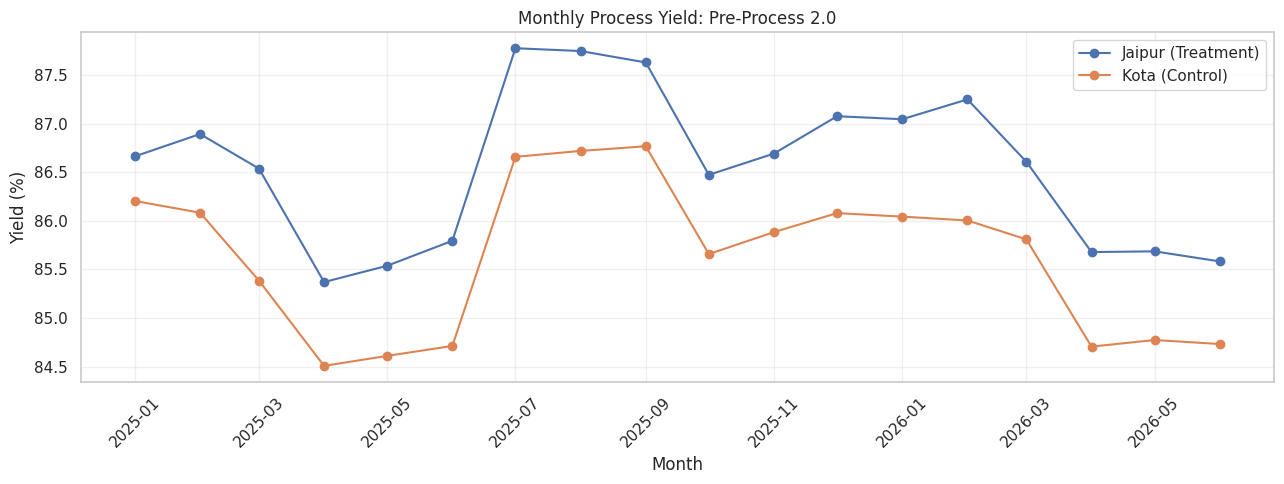

In [ ]:

# PRE-TREATMENT PARALLEL TRENDS: MONTHLY YIELD


matched = did_data.loc[did_data["_merge"] == "both"].copy()

matched["month"] = (
    matched["batch_date"].dt.to_period("M").dt.to_timestamp()
)

# Keep only the pre-Process 2.0 period
pre_period = matched[
    matched["batch_date"] < "2026-07-01"
].copy()

# Aggregate monthly production totals by plant
monthly_jaipur = pre_period.groupby("month").agg(
    raw_input=("raw_input_kg_jaipur", "sum"),
    finished_output=("finished_output_kg_jaipur", "sum")
)

monthly_kota = pre_period.groupby("month").agg(
    raw_input=("raw_input_kg_kota", "sum"),
    finished_output=("finished_output_kg_kota", "sum")
)

monthly_jaipur["yield_pct"] = (
    monthly_jaipur["finished_output"]
    / monthly_jaipur["raw_input"] * 100
)

monthly_kota["yield_pct"] = (
    monthly_kota["finished_output"]
    / monthly_kota["raw_input"] * 100
)

monthly_trends = pd.DataFrame({
    "Jaipur": monthly_jaipur["yield_pct"],
    "Kota": monthly_kota["yield_pct"]
})

print("MONTHLY PRE-TREATMENT YIELD:")
display(monthly_trends.round(2))

# Plot monthly trends
plt.figure(figsize=(13, 5))

plt.plot(
    monthly_trends.index, monthly_trends["Jaipur"],
    marker="o", label="Jaipur (Treatment)"
)

plt.plot(
    monthly_trends.index, monthly_trends["Kota"],
    marker="o", label="Kota (Control)"
)

plt.title("Monthly Process Yield: Pre-Process 2.0")
plt.xlabel("Month")
plt.ylabel("Yield (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

# PRE-TREATMENT PARALLEL TRENDS TEST


# Calculate monthly Jaipur-Kota yield gap
trend_test = monthly_trends.copy()
trend_test["yield_gap"] = (
    trend_test["Jaipur"] - trend_test["Kota"]
)

# Create sequential monthly time index
trend_test["month_index"] = np.arange(len(trend_test))

# Test whether the yield gap changes over time
X = sm.add_constant(trend_test["month_index"])

model = sm.OLS(
    trend_test["yield_gap"], X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 2}
)

slope = model.params["month_index"]
ci_low, ci_high = model.conf_int().loc["month_index"]

print("PRE-TREND TEST: JAIPUR-KOTA YIELD GAP")
print("-------------------------------------")
print("Average yield gap (percentage points):",
      round(trend_test["yield_gap"].mean(), 3))
print("Estimated monthly gap trend (pp/month):",
      round(slope, 4))
print("95% confidence interval:",
      (round(ci_low, 4), round(ci_high, 4)))
print("P-value:", round(model.pvalues["month_index"], 4))

if model.pvalues["month_index"] < 0.05:
    print("\nRESULT: Significant differential pre-trend detected.")
else:
    print("\nRESULT: No statistically significant linear differential pre-trend detected.")

print("\nMONTHLY YIELD GAP:")
display(trend_test[["Jaipur", "Kota", "yield_gap"]].round(3))

PRE-TREND TEST: JAIPUR-KOTA YIELD GAP
-------------------------------------
Average yield gap (percentage points): 0.929
Estimated monthly gap trend (pp/month): 0.0064
95% confidence interval: (-0.0107, 0.0235)
P-value: 0.4663

RESULT: No statistically significant linear differential pre-trend detected.

MONTHLY YIELD GAP:


,Jaipur,Kota,yield_gap
month,,,
2025-01-01,86.664,86.205,0.459
2025-02-01,86.894,86.084,0.810
2025-03-01,86.538,85.385,1.153
2025-04-01,85.370,84.507,0.863
2025-05-01,85.538,84.610,0.928
2025-06-01,85.795,84.712,1.083
2025-07-01,87.778,86.659,1.119
2025-08-01,87.749,86.720,1.028
2025-09-01,87.631,86.768,0.863


In [ ]:

# DIFFERENCE-IN-DIFFERENCES: PROCESS YIELD


# Aggregate matched line observations to daily plant totals
daily_did = matched.groupby("batch_date").agg(
    jaipur_input=("raw_input_kg_jaipur", "sum"),
    jaipur_output=("finished_output_kg_jaipur", "sum"),
    kota_input=("raw_input_kg_kota", "sum"),
    kota_output=("finished_output_kg_kota", "sum")
).reset_index()

# Calculate daily plant-level yields
daily_did["jaipur_yield"] = (
    daily_did["jaipur_output"] / daily_did["jaipur_input"] * 100
)

daily_did["kota_yield"] = (
    daily_did["kota_output"] / daily_did["kota_input"] * 100
)

# Calculate daily treatment-control gap
daily_did["yield_gap"] = (
    daily_did["jaipur_yield"] - daily_did["kota_yield"]
)

daily_did["post"] = (
    daily_did["batch_date"] >= "2026-07-01"
).astype(int)

# Descriptive pre/post comparison
period_summary = daily_did.groupby("post").agg(
    days=("batch_date", "count"),
    jaipur_yield=("jaipur_yield", "mean"),
    kota_yield=("kota_yield", "mean"),
    yield_gap=("yield_gap", "mean")
).rename(index={0: "Pre", 1: "Post"})

print("PRE/POST YIELD COMPARISON:")
display(period_summary.round(3))

# Estimate DiD using the daily yield gap
X = sm.add_constant(daily_did["post"])

did_model = sm.OLS(
    daily_did["yield_gap"], X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 7}
)

did_effect = did_model.params["post"]
did_ci = did_model.conf_int().loc["post"]
did_p = did_model.pvalues["post"]

print("\nDIFFERENCE-IN-DIFFERENCES RESULT")
print("--------------------------------")
print("Estimated treatment effect (percentage points):",
      round(did_effect, 3))
print("95% confidence interval:",
      (round(did_ci.iloc[0], 3), round(did_ci.iloc[1], 3)))
print("P-value:", round(did_p, 4))
print("Daily observations:", len(daily_did))

if did_p < 0.05:
    print("\nStatistical result: Significant estimated effect.")
else:
    print("\nStatistical result: No statistically significant estimated effect.")

PRE/POST YIELD COMPARISON:


,days,jaipur_yield,kota_yield,yield_gap
post,,,,
Pre,546,86.557,85.602,0.955
Post,92,88.863,86.944,1.919



DIFFERENCE-IN-DIFFERENCES RESULT
--------------------------------
Estimated treatment effect (percentage points): 0.965
95% confidence interval: (np.float64(0.7), np.float64(1.23))
P-value: 0.0
Daily observations: 638

Statistical result: Significant estimated effect.


In [ ]:

# SECONDARY DiD OUTCOMES: WASTAGE & REJECTION


secondary_daily = matched.groupby("batch_date").agg(
    jaipur_input=("raw_input_kg_jaipur", "sum"),
    jaipur_waste=("waste_kg_jaipur", "sum"),
    jaipur_tested=("units_tested_jaipur", "sum"),
    jaipur_rejected=("units_rejected_jaipur", "sum"),

    kota_input=("raw_input_kg_kota", "sum"),
    kota_waste=("waste_kg_kota", "sum"),
    kota_tested=("units_tested_kota", "sum"),
    kota_rejected=("units_rejected_kota", "sum")
).reset_index()

# Calculate daily rates from underlying totals
for plant in ["jaipur", "kota"]:
    secondary_daily[f"{plant}_wastage"] = (
        secondary_daily[f"{plant}_waste"]
        / secondary_daily[f"{plant}_input"] * 100
    )

    secondary_daily[f"{plant}_rejection"] = (
        secondary_daily[f"{plant}_rejected"]
        / secondary_daily[f"{plant}_tested"] * 100
    )

secondary_daily["post"] = (
    secondary_daily["batch_date"] >= "2026-07-01"
).astype(int)

results = []

for metric in ["wastage", "rejection"]:

    secondary_daily[f"{metric}_gap"] = (
        secondary_daily[f"jaipur_{metric}"]
        - secondary_daily[f"kota_{metric}"]
    )

    X = sm.add_constant(secondary_daily["post"])

    model = sm.OLS(
        secondary_daily[f"{metric}_gap"], X
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 7}
    )

    ci = model.conf_int().loc["post"]

    results.append({
        "Outcome": metric.capitalize(),
        "DiD Effect (pp)": model.params["post"],
        "95% CI Lower": ci.iloc[0],
        "95% CI Upper": ci.iloc[1],
        "P-value": model.pvalues["post"]
    })

results_df = pd.DataFrame(results)

print("SECONDARY OUTCOME DiD RESULTS:")
display(results_df.round(4))

SECONDARY OUTCOME DiD RESULTS:


,Outcome,DiD Effect (pp),95% CI Lower,95% CI Upper,P-value
0,Wastage,-0.979,-1.246,-0.712,0.000
1,Rejection,-0.291,-0.381,-0.200,0.000


In [ ]:
# LINE-LEVEL DiD: TREATMENT HETEROGENEITY

line_data = did_data.loc[
    did_data["_merge"] == "both"
].copy()

line_data["post"] = (
    line_data["batch_date"] >= "2026-07-01"
).astype(int)

outcomes = {
    "Yield": ("yield_pct_jaipur", "yield_pct_kota"),
    "Wastage": ("wastage_pct_jaipur", "wastage_pct_kota"),
    "Rejection": ("rejection_rate_pct_jaipur",
                  "rejection_rate_pct_kota")
}

line_results = []

for line in sorted(line_data["line_id"].unique()):

    subset = line_data[line_data["line_id"] == line].copy()

    for outcome, (jaipur_col, kota_col) in outcomes.items():

        subset["gap"] = subset[jaipur_col] - subset[kota_col]

        X = sm.add_constant(subset["post"])

        model = sm.OLS(
            subset["gap"], X
        ).fit(
            cov_type="HAC",
            cov_kwds={"maxlags": 7}
        )

        ci = model.conf_int().loc["post"]

        line_results.append({
            "Line": line,
            "Outcome": outcome,
            "DiD Effect (pp)": model.params["post"],
            "95% CI Lower": ci.iloc[0],
            "95% CI Upper": ci.iloc[1],
            "P-value": model.pvalues["post"],
            "Matched Days": len(subset)
        })

line_results_df = pd.DataFrame(line_results)

print("LINE-LEVEL DiD RESULTS:")
display(line_results_df.round(4))

LINE-LEVEL DiD RESULTS:


,Line,Outcome,DiD Effect (pp),95% CI Lower,95% CI Upper,P-value,Matched Days
0,L1,Yield,1.095,0.770,1.421,0.000,632
1,L1,Wastage,-1.111,-1.458,-0.765,0.000,632
2,L1,Rejection,-0.295,-0.400,-0.190,0.000,632
3,L2,Yield,0.879,0.536,1.222,0.000,630
4,L2,Wastage,-0.873,-1.202,-0.543,0.000,630
5,L2,Rejection,-0.296,-0.402,-0.190,0.000,630
6,L3,Yield,1.162,0.862,1.462,0.000,633
7,L3,Wastage,-1.210,-1.530,-0.890,0.000,633
8,L3,Rejection,-0.333,-0.501,-0.164,0.000,633


In [ ]:
# SMARTBLANCH: EXPERIMENT DATA AUDIT

experiment = csv_files["06_experiment_smartblanch.csv"].copy()

print("DATASET SHAPE:", experiment.shape)

print("\nCOLUMN STRUCTURE:")
display(pd.DataFrame({
    "Column": experiment.columns,
    "Data Type": experiment.dtypes.astype(str).values,
    "Missing Values": experiment.isna().sum().values
}))

print("\nEXPERIMENT SAMPLE:")
display(experiment.head(8))

print("\nVARIANT COUNTS:")
display(experiment["variant"].value_counts().to_frame("Batches"))

print("\nVARIANT DISTRIBUTION (%):")
display(
    (experiment["variant"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

DATASET SHAPE: (1260, 17)

COLUMN STRUCTURE:


,Column,Data Type,Missing Values
0,batch_id,object,0
1,batch_date,object,0
2,line_id,object,0
3,shift,object,0
4,product,object,0
5,variant,object,0
6,raw_input_kg,float64,0
7,lot_pretest_yield_pct,float64,0
8,raw_moisture_pct,float64,0
9,pre_period_line_product_yield_pct,float64,0



EXPERIMENT SAMPLE:


,batch_id,batch_date,line_id,shift,product,variant,raw_input_kg,lot_pretest_yield_pct,raw_moisture_pct,pre_period_line_product_yield_pct,yield_pct,wastage_pct,units_tested,units_rejected,rejection_rate_pct,energy_kwh_per_kg,cycle_time_min
0,EXP-00001,2026-10-01,L1,Morning,Aloo Tikki,treatment,1144.500,87.190,79.700,90.222,88.007,8.218,153,3,1.961,0.291,103.000
1,EXP-00002,2026-10-01,L3,Morning,Paneer Tikka,treatment,1498.500,85.190,76.700,85.861,88.602,6.186,224,8,3.571,0.279,103.900
2,EXP-00003,2026-10-01,L2,Morning,Green Peas,control,1809.400,92.970,78.100,94.143,93.009,2.028,198,4,2.020,0.285,98.600
3,EXP-00004,2026-10-01,L2,Morning,Mixed Veg,treatment,2206.100,89.560,75.300,91.638,94.576,1.649,183,5,2.732,0.243,105.000
4,EXP-00005,2026-10-01,L3,Morning,Veg Momos,treatment,2090.000,82.170,76.800,82.781,84.208,12.170,165,9,5.455,0.306,93.800
5,EXP-00006,2026-10-01,L1,Morning,Veg Momos,control,1325.000,82.940,76.100,84.272,84.513,11.630,169,7,4.142,0.338,102.600
6,EXP-00007,2026-10-01,L2,Morning,Green Peas,treatment,2056.700,92.890,84.300,94.143,93.045,4.014,183,1,0.546,0.307,97.100
7,EXP-00008,2026-10-01,L1,Morning,Paneer Tikka,control,1343.700,86.180,74.900,87.370,88.480,6.929,243,9,3.704,0.266,104.600



VARIANT COUNTS:


,Batches
variant,
control,676
treatment,584



VARIANT DISTRIBUTION (%):


,Percentage
variant,
control,53.650
treatment,46.350


In [ ]:

# SMARTBLANCH: SAMPLE RATIO MISMATCH TEST


from scipy.stats import chisquare, binomtest

experiment["batch_date"] = pd.to_datetime(experiment["batch_date"])

# Overall allocation test against 50:50
counts = experiment["variant"].value_counts().reindex(
    ["control", "treatment"], fill_value=0
)

observed = counts.values
expected = np.array([len(experiment) / 2] * 2)

chi_stat, chi_p = chisquare(observed, f_exp=expected)

exact_test = binomtest(
    int(counts["treatment"]),
    n=len(experiment),
    p=0.5,
    alternative="two-sided"
)

print("OVERALL SRM TEST")
print("----------------")
print("Control:", counts["control"])
print("Treatment:", counts["treatment"])
print("Expected per group:", int(len(experiment) / 2))
print("Chi-square statistic:", round(chi_stat, 4))
print("Chi-square p-value:", round(chi_p, 6))
print("Exact binomial p-value:", round(exact_test.pvalue, 6))

# Inspect allocation within randomisation blocks
block_counts = experiment.groupby(
    ["batch_date", "line_id", "shift", "variant"]
).size().unstack(fill_value=0)

for variant in ["control", "treatment"]:
    if variant not in block_counts.columns:
        block_counts[variant] = 0

block_counts["total"] = (
    block_counts["control"] + block_counts["treatment"]
)

block_counts["allocation_gap"] = (
    block_counts["treatment"] - block_counts["control"]
)

print("\nBLOCK-LEVEL ALLOCATION")
print("----------------------")
print("Total date-line-shift blocks:", len(block_counts))
print("Blocks with both variants:",
      ((block_counts["control"] > 0) &
       (block_counts["treatment"] > 0)).sum())
print("Blocks with control only:",
      ((block_counts["control"] > 0) &
       (block_counts["treatment"] == 0)).sum())
print("Blocks with treatment only:",
      ((block_counts["treatment"] > 0) &
       (block_counts["control"] == 0)).sum())

print("\nLARGEST ALLOCATION IMBALANCES:")
display(
    block_counts.sort_values(
        "allocation_gap",
        key=lambda x: x.abs(),
        ascending=False
    ).head(15)
)

OVERALL SRM TEST
----------------
Control: 676
Treatment: 584
Expected per group: 630
Chi-square statistic: 6.7175
Chi-square p-value: 0.009547
Exact binomial p-value: 0.01033

BLOCK-LEVEL ALLOCATION
----------------------
Total date-line-shift blocks: 280
Blocks with both variants: 240
Blocks with control only: 34
Blocks with treatment only: 6

LARGEST ALLOCATION IMBALANCES:


,,variant,control,treatment,total,allocation_gap
batch_date,line_id,shift,,,,
2026-10-05,L3,Night,7,0,7,-7
2026-10-13,L3,Night,5,0,5,-5
2026-10-14,L3,Night,4,0,4,-4
2026-10-21,L3,Night,4,0,4,-4
2026-10-29,L3,Night,3,0,3,-3
2026-10-09,L3,Night,3,0,3,-3
2026-10-22,L3,Evening,4,1,5,-3
2026-10-23,L3,Night,3,0,3,-3
2026-10-24,L3,Night,3,0,3,-3


In [ ]:

# SRM INVESTIGATION: LINE × SHIFT ALLOCATION


# Allocation by line and shift
allocation = experiment.pivot_table(
    index=["line_id", "shift"],
    columns="variant",
    values="batch_id",
    aggfunc="count",
    fill_value=0
)

for variant in ["control", "treatment"]:
    if variant not in allocation.columns:
        allocation[variant] = 0

allocation["total"] = (
    allocation["control"] + allocation["treatment"]
)

allocation["treatment_share_pct"] = (
    allocation["treatment"] / allocation["total"] * 100
)

allocation["difference_from_50pp"] = (
    allocation["treatment_share_pct"] - 50
)

print("ALLOCATION BY LINE AND SHIFT:")
display(allocation.round(2))

# Overall allocation by line
print("\nALLOCATION BY LINE:")
display(
    experiment.groupby(["line_id", "variant"])
    .size()
    .unstack(fill_value=0)
)

# Overall allocation by shift
print("\nALLOCATION BY SHIFT:")
display(
    experiment.groupby(["shift", "variant"])
    .size()
    .unstack(fill_value=0)
)

# Dates with zero treatment batches
zero_treatment_blocks = block_counts[
    block_counts["treatment"] == 0
].reset_index()

print("\nBLOCKS WITH ZERO TREATMENT:")
display(zero_treatment_blocks)

ALLOCATION BY LINE AND SHIFT:


variant          control  treatment  total  treatment_share_pct  \
line_id shift                                                     
L1      Evening       76         80    156               51.280   
        Morning       72         72    144               50.000   
        Night         83         79    162               48.770   
L2      Evening       69         73    142               51.410   
        Morning       72         68    140               48.570   
        Night         73         74    147               50.340   
L3      Evening       77         51    128               39.840   
        Morning       74         79    153               51.630   
        Night         80          8     88                9.090   

variant          difference_from_50pp  
line_id shift                          
L1      Evening                 1.280  
        Morning                 0.000  
        Night                  -1.230  
L2      Evening                 1.410  
        Morning                -1.430  
        Night                   0.340  
L3      Evening               -10.160  
        Morning                 1.630  
        Night                 -40.910


ALLOCATION BY LINE:


variant,control,treatment
line_id,,
L1,231,231
L2,214,215
L3,231,138



ALLOCATION BY SHIFT:


variant,control,treatment
shift,,
Evening,222,204
Morning,218,219
Night,236,161



BLOCKS WITH ZERO TREATMENT:


variant,batch_date,line_id,shift,control,treatment,total,allocation_gap
0,2026-10-01,L3,Night,2,0,2,-2
1,2026-10-03,L3,Night,2,0,2,-2
2,2026-10-04,L2,Night,1,0,1,-1
3,2026-10-04,L3,Night,1,0,1,-1
4,2026-10-05,L3,Night,7,0,7,-7
5,2026-10-07,L3,Night,3,0,3,-3
6,2026-10-08,L3,Evening,1,0,1,-1
7,2026-10-08,L3,Night,3,0,3,-3
8,2026-10-09,L3,Night,3,0,3,-3
9,2026-10-10,L3,Night,3,0,3,-3


In [ ]:

# L3 NIGHT: DAILY ALLOCATION INVESTIGATION


l3_night = experiment[
    (experiment["line_id"] == "L3") &
    (experiment["shift"] == "Night")
].copy()

daily_allocation = l3_night.pivot_table(
    index="batch_date",
    columns="variant",
    values="batch_id",
    aggfunc="count",
    fill_value=0
)

for variant in ["control", "treatment"]:
    if variant not in daily_allocation.columns:
        daily_allocation[variant] = 0

daily_allocation["total"] = (
    daily_allocation["control"] +
    daily_allocation["treatment"]
)

daily_allocation["treatment_share_pct"] = (
    daily_allocation["treatment"] /
    daily_allocation["total"] * 100
)

print("L3 NIGHT DAILY ALLOCATION:")
display(daily_allocation)

print("\nL3 NIGHT SUMMARY:")
print("Experiment dates represented:", len(daily_allocation))
print("Dates with zero treatment:",
      (daily_allocation["treatment"] == 0).sum())
print("Dates with both variants:",
      ((daily_allocation["control"] > 0) &
       (daily_allocation["treatment"] > 0)).sum())
print("Dates with treatment batches:",
      (daily_allocation["treatment"] > 0).sum())

print("\nL3 NIGHT TOTALS:")
display(
    l3_night.groupby("variant").agg(
        batches=("batch_id", "count"),
        first_date=("batch_date", "min"),
        last_date=("batch_date", "max")
    )
)

L3 NIGHT DAILY ALLOCATION:


variant,control,treatment,total,treatment_share_pct
batch_date,,,,
2026-10-01,2,0,2,0.000
2026-10-02,3,1,4,25.000
2026-10-03,2,0,2,0.000
2026-10-04,1,0,1,0.000
2026-10-05,7,0,7,0.000
2026-10-06,2,2,4,50.000
2026-10-07,3,0,3,0.000
2026-10-08,3,0,3,0.000
2026-10-09,3,0,3,0.000



L3 NIGHT SUMMARY:
Experiment dates represented: 31
Dates with zero treatment: 24
Dates with both variants: 7
Dates with treatment batches: 7

L3 NIGHT TOTALS:


,batches,first_date,last_date
variant,,,
control,80,2026-10-01,2026-11-01
treatment,8,2026-10-02,2026-10-31


In [ ]:

# SMARTBLANCH: BASELINE COVARIATE BALANCE


baseline_vars = [
    "raw_input_kg",
    "lot_pretest_yield_pct",
    "raw_moisture_pct",
    "pre_period_line_product_yield_pct"
]

balance_results = []

for col in baseline_vars:

    control = experiment.loc[
        experiment["variant"] == "control", col
    ]

    treatment = experiment.loc[
        experiment["variant"] == "treatment", col
    ]

    pooled_sd = np.sqrt(
        (control.var(ddof=1) + treatment.var(ddof=1)) / 2
    )

    smd = (
        treatment.mean() - control.mean()
    ) / pooled_sd

    balance_results.append({
        "Covariate": col,
        "Control Mean": control.mean(),
        "Treatment Mean": treatment.mean(),
        "Difference": treatment.mean() - control.mean(),
        "Standardised Mean Difference": smd
    })

balance_df = pd.DataFrame(balance_results)

print("PRE-TREATMENT COVARIATE BALANCE:")
display(balance_df.round(4))

print("\nCATEGORICAL DISTRIBUTION: LINE")
display(
    pd.crosstab(
        experiment["line_id"],
        experiment["variant"],
        normalize="columns"
    ).round(3)
)

print("\nCATEGORICAL DISTRIBUTION: SHIFT")
display(
    pd.crosstab(
        experiment["shift"],
        experiment["variant"],
        normalize="columns"
    ).round(3)
)

print("\nCATEGORICAL DISTRIBUTION: PRODUCT")
display(
    pd.crosstab(
        experiment["product"],
        experiment["variant"],
        normalize="columns"
    ).round(3)
)

PRE-TREATMENT COVARIATE BALANCE:


,Covariate,Control Mean,Treatment Mean,Difference,Standardised Mean Difference
0,raw_input_kg,1700.141,1714.990,14.849,0.031
1,lot_pretest_yield_pct,87.088,87.252,0.163,0.042
2,raw_moisture_pct,78.027,77.978,-0.049,-0.022
3,pre_period_line_product_yield_pct,88.590,88.898,0.308,0.086



CATEGORICAL DISTRIBUTION: LINE


variant,control,treatment
line_id,,
L1,0.342,0.396
L2,0.317,0.368
L3,0.342,0.236



CATEGORICAL DISTRIBUTION: SHIFT


variant,control,treatment
shift,,
Evening,0.328,0.349
Morning,0.322,0.375
Night,0.349,0.276



CATEGORICAL DISTRIBUTION: PRODUCT


variant,control,treatment
product,,
Aloo Tikki,0.291,0.295
Green Peas,0.120,0.135
Mixed Veg,0.178,0.199
Paneer Tikka,0.192,0.144
Veg Momos,0.219,0.228


In [ ]:

# SMARTBLANCH: UNADJUSTED OUTCOME COMPARISON


outcomes = {
    "Yield (%)": "yield_pct",
    "Wastage (%)": "wastage_pct",
    "Rejection rate (%)": "rejection_rate_pct",
    "Energy (kWh/kg)": "energy_kwh_per_kg",
    "Cycle time (min)": "cycle_time_min"
}

comparison_results = []

for label, col in outcomes.items():

    control = experiment.loc[
        experiment["variant"] == "control", col
    ].dropna()

    treatment = experiment.loc[
        experiment["variant"] == "treatment", col
    ].dropna()

    # Welch's independent-samples t-test
    test = stats.ttest_ind(
        treatment, control, equal_var=False
    )

    # Difference: treatment minus control
    difference = treatment.mean() - control.mean()

    # Welch confidence interval
    var_t = treatment.var(ddof=1) / len(treatment)
    var_c = control.var(ddof=1) / len(control)

    se = np.sqrt(var_t + var_c)

    df = (var_t + var_c) ** 2 / (
        (var_t ** 2 / (len(treatment) - 1)) +
        (var_c ** 2 / (len(control) - 1))
    )

    critical_value = stats.t.ppf(0.975, df)

    comparison_results.append({
        "Outcome": label,
        "Control Mean": control.mean(),
        "Treatment Mean": treatment.mean(),
        "Difference (T-C)": difference,
        "95% CI Lower": difference - critical_value * se,
        "95% CI Upper": difference + critical_value * se,
        "P-value": test.pvalue
    })

comparison_df = pd.DataFrame(comparison_results)

print("UNADJUSTED SMARTBLANCH OUTCOME COMPARISON:")
display(comparison_df.round(4))

UNADJUSTED SMARTBLANCH OUTCOME COMPARISON:


,Outcome,Control Mean,Treatment Mean,Difference (T-C),95% CI Lower,95% CI Upper,P-value
0,Yield (%),87.681,88.495,0.814,0.320,1.308,0.001
1,Wastage (%),8.257,7.555,-0.702,-1.192,-0.211,0.005
2,Rejection rate (%),2.592,2.602,0.010,-0.151,0.170,0.905
3,Energy (kWh/kg),0.299,0.287,-0.012,-0.015,-0.010,0.000
4,Cycle time (min),98.604,100.455,1.851,1.188,2.513,0.000


In [ ]:


# SMARTBLANCH: BLOCK-ADJUSTED TREATMENT EFFECTS


# Create randomisation block identifier
experiment["block_id"] = (
    experiment["batch_date"].astype(str) + "_" +
    experiment["line_id"].astype(str) + "_" +
    experiment["shift"].astype(str)
)

# Identify blocks containing both control and treatment
block_variant_counts = (
    experiment.groupby("block_id")["variant"].nunique()
)

mixed_blocks = block_variant_counts[
    block_variant_counts == 2
].index

# Retain only blocks with both variants
block_data = experiment[
    experiment["block_id"].isin(mixed_blocks)
].copy()

# Binary treatment indicator
block_data["treatment"] = (
    block_data["variant"] == "treatment"
).astype(int)

outcomes = {
    "Yield (%)": "yield_pct",
    "Wastage (%)": "wastage_pct",
    "Rejection rate (%)": "rejection_rate_pct",
    "Energy (kWh/kg)": "energy_kwh_per_kg",
    "Cycle time (min)": "cycle_time_min"
}

block_results = []

for label, col in outcomes.items():

    model = smf.ols(
        f"{col} ~ treatment + C(block_id)",
        data=block_data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": block_data["block_id"]}
    )

    effect = model.params["treatment"]
    ci_lower, ci_upper = model.conf_int().loc["treatment"]

    block_results.append({
        "Outcome": label,
        "Adjusted Effect (T-C)": effect,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "P-value": model.pvalues["treatment"],
        "Observations": int(model.nobs),
        "Blocks": block_data["block_id"].nunique()
    })

block_results_df = pd.DataFrame(block_results)

print("BLOCK-ADJUSTED SMARTBLANCH RESULTS:")
print(f"Original experiment batches: {len(experiment)}")
print(f"Batches in mixed blocks: {len(block_data)}")
print(f"Mixed blocks: {block_data['block_id'].nunique()}")

display(block_results_df.round(4))


BLOCK-ADJUSTED SMARTBLANCH RESULTS:
Original experiment batches: 1260
Batches in mixed blocks: 1179
Mixed blocks: 240


,Outcome,Adjusted Effect (T-C),95% CI Lower,95% CI Upper,P-value,Observations,Blocks
0,Yield (%),0.246,-0.184,0.677,0.262,1179,240
1,Wastage (%),-0.151,-0.585,0.284,0.496,1179,240
2,Rejection rate (%),0.166,0.002,0.331,0.047,1179,240
3,Energy (kWh/kg),-0.012,-0.015,-0.010,0.000,1179,240
4,Cycle time (min),1.883,1.127,2.639,0.000,1179,240


In [ ]:


# SMARTBLANCH: CUPED-STYLE REGRESSION


pre_treatment_covariates = [
    "lot_pretest_yield_pct",
    "raw_moisture_pct",
    "pre_period_line_product_yield_pct",
    "raw_input_kg"
]

adjusted_results = []

for label, col in outcomes.items():

    formula = (
        f"{col} ~ treatment + "
        + " + ".join(pre_treatment_covariates)
        + " + C(block_id)"
    )

    model = smf.ols(
        formula,
        data=block_data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": block_data["block_id"]}
    )

    effect = model.params["treatment"]
    ci_lower, ci_upper = model.conf_int().loc["treatment"]

    adjusted_results.append({
        "Outcome": label,
        "Adjusted Effect (T-C)": effect,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "P-value": model.pvalues["treatment"],
        "R-squared": model.rsquared
    })

cuped_results_df = pd.DataFrame(adjusted_results)

print("CUPED-STYLE REGRESSION RESULTS:")
display(cuped_results_df.round(4))


CUPED-STYLE REGRESSION RESULTS:


,Outcome,Adjusted Effect (T-C),95% CI Lower,95% CI Upper,P-value,R-squared
0,Yield (%),0.443,0.188,0.697,0.001,0.856
1,Wastage (%),-0.344,-0.610,-0.077,0.011,0.832
2,Rejection rate (%),0.143,-0.012,0.299,0.071,0.422
3,Energy (kWh/kg),-0.012,-0.015,-0.010,0.000,0.287
4,Cycle time (min),1.861,1.103,2.619,0.000,0.232


In [ ]:


# SMARTBLANCH: SEGMENT-LEVEL TREATMENT EFFECTS
# Primary outcome: Yield


segments = ["line_id", "shift", "product"]
segment_results = []

for segment in segments:

    for group in sorted(block_data[segment].dropna().unique()):

        subset = block_data[
            block_data[segment] == group
        ].copy()

        control_n = (subset["treatment"] == 0).sum()
        treatment_n = (subset["treatment"] == 1).sum()

        # Require sufficient observations in both groups
        if control_n < 20 or treatment_n < 20:
            segment_results.append({
                "Segment": segment,
                "Category": group,
                "Control N": control_n,
                "Treatment N": treatment_n,
                "Adjusted Effect (pp)": np.nan,
                "95% CI Lower": np.nan,
                "95% CI Upper": np.nan,
                "P-value": np.nan,
                "Status": "Insufficient sample"
            })
            continue

        # Ensure enough mixed blocks for within-block estimation
        mixed_segment_blocks = (
            subset.groupby("block_id")["treatment"].nunique()
        )
        mixed_segment_blocks = mixed_segment_blocks[
            mixed_segment_blocks == 2
        ].index

        subset = subset[
            subset["block_id"].isin(mixed_segment_blocks)
        ].copy()

        if subset["treatment"].nunique() < 2:
            continue

        formula = (
            "yield_pct ~ treatment + "
            + " + ".join(pre_treatment_covariates)
            + " + C(block_id)"
        )

        model = smf.ols(
            formula,
            data=subset
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": subset["block_id"]}
        )

        effect = model.params["treatment"]
        ci_lower, ci_upper = model.conf_int().loc["treatment"]

        segment_results.append({
            "Segment": segment,
            "Category": group,
            "Control N": control_n,
            "Treatment N": treatment_n,
            "Adjusted Effect (pp)": effect,
            "95% CI Lower": ci_lower,
            "95% CI Upper": ci_upper,
            "P-value": model.pvalues["treatment"],
            "Status": "Estimated"
        })

segment_results_df = pd.DataFrame(segment_results)

print("SMARTBLANCH SEGMENT-LEVEL YIELD EFFECTS:")
display(
    segment_results_df.round(4)
)


SMARTBLANCH SEGMENT-LEVEL YIELD EFFECTS:


,Segment,Category,Control N,Treatment N,Adjusted Effect (pp),95% CI Lower,95% CI Upper,P-value,Status
0,line_id,L1,228,231,0.337,-0.071,0.745,0.106,Estimated
1,line_id,L2,212,211,0.847,0.442,1.253,0.000,Estimated
2,line_id,L3,161,136,0.072,-0.407,0.551,0.767,Estimated
3,shift,Evening,214,202,0.246,-0.160,0.652,0.234,Estimated
4,shift,Morning,217,216,0.628,0.191,1.065,0.005,Estimated
5,shift,Night,170,160,0.453,-0.053,0.960,0.079,Estimated
6,product,Aloo Tikki,174,169,0.895,0.305,1.486,0.003,Estimated
7,product,Green Peas,80,79,0.985,0.267,1.703,0.007,Estimated
8,product,Mixed Veg,119,114,0.609,-0.074,1.291,0.081,Estimated
9,product,Paneer Tikka,107,83,-0.870,-1.744,0.003,0.051,Estimated


In [ ]:


# CELL 32: SMARTBLANCH POWER ANALYSIS


from statsmodels.stats.power import TTestIndPower
from math import ceil

# 1. Historical Q2 2026 baseline
baseline_q2 = batches[
    (batches["batch_date"] >= "2026-04-01") &
    (batches["batch_date"] <= "2026-06-30")
].copy()

baseline_yield = baseline_q2["yield_pct"].dropna()

baseline_mean = baseline_yield.mean()
baseline_sd = baseline_yield.std(ddof=1)

print("HISTORICAL BASELINE")
print(f"Number of batches: {len(baseline_yield)}")
print(f"Mean yield: {baseline_mean:.3f}%")
print(f"Yield standard deviation: {baseline_sd:.3f} pp")

# 2. Power analysis assumptions
power_model = TTestIndPower()

alpha = 0.05
target_power = 0.80
contingency = 0.10

mde_values = [0.30, 0.50, 0.75, 1.00]

results = []

for mde in mde_values:

    effect_size = mde / baseline_sd

    required_n = power_model.solve_power(
        effect_size=effect_size,
        power=target_power,
        alpha=alpha,
        ratio=1.0,
        alternative="two-sided"
    )

    required_n = ceil(required_n)
    adjusted_n = ceil(required_n / (1 - contingency))

    results.append({
        "MDE (pp)": mde,
        "Cohen's d": effect_size,
        "N per group": required_n,
        "N per group + 10%": adjusted_n,
        "Total sample required": adjusted_n * 2
    })

power_df = pd.DataFrame(results)

print("\nREQUIRED SAMPLE SIZE")
display(power_df.round(3))

# 3. Observed experiment throughput
experiment_days = experiment["batch_date"].nunique()
daily_batches = len(experiment) / experiment_days

print("\nEXPERIMENT THROUGHPUT")
print(f"Experiment days: {experiment_days}")
print(f"Total batches: {len(experiment)}")
print(f"Average batches per day: {daily_batches:.2f}")

# 4. Estimated duration
power_df["Estimated duration (days)"] = (
    power_df["Total sample required"] / daily_batches
).apply(ceil)

print("\nESTIMATED EXPERIMENT DURATION")
display(
    power_df[
        ["MDE (pp)", "Total sample required",
         "Estimated duration (days)"]
    ]
)

# 5. Detectable effect with current sample size
control_n = (experiment["variant"] == "control").sum()
treatment_n = (experiment["variant"] == "treatment").sum()

balanced_n = min(control_n, treatment_n)

detectable_d = power_model.solve_power(
    nobs1=balanced_n,
    power=target_power,
    alpha=alpha,
    ratio=1.0,
    alternative="two-sided"
)

detectable_mde = detectable_d * baseline_sd

print("\nCURRENT EXPERIMENT POWER")
print(f"Control batches: {control_n}")
print(f"Treatment batches: {treatment_n}")
print(f"Conservative group size: {balanced_n}")
print(f"Approximate detectable MDE: {detectable_mde:.3f} pp")


HISTORICAL BASELINE
Number of batches: 3421
Mean yield: 85.338%
Yield standard deviation: 4.383 pp

REQUIRED SAMPLE SIZE


,MDE (pp),Cohen's d,N per group,N per group + 10%,Total sample required
0,0.300,0.068,3352,3725,7450
1,0.500,0.114,1208,1343,2686
2,0.750,0.171,538,598,1196
3,1.000,0.228,303,337,674



EXPERIMENT THROUGHPUT
Experiment days: 32
Total batches: 1260
Average batches per day: 39.38

ESTIMATED EXPERIMENT DURATION


,MDE (pp),Total sample required,Estimated duration (days)
0,0.300,7450,190
1,0.500,2686,69
2,0.750,1196,31
3,1.000,674,18



CURRENT EXPERIMENT POWER
Control batches: 676
Treatment batches: 584
Conservative group size: 584
Approximate detectable MDE: 0.719 pp


In [ ]:


# CELL 33: SMARTBLANCH EXPERIMENT REDESIGN


# 1. Experiment design assumptions

design = {
    "Experiment": "SmartBlanch",
    "Primary outcome": "Production yield (%)",
    "Minimum detectable effect (pp)": 0.50,
    "Significance level": 0.05,
    "Statistical power": 0.80,
    "Allocation ratio": "50:50",
    "Randomisation unit": "Production batch",
    "Randomisation strata": "Date x Line x Shift x Product",
    "Confidence level": "95%",
    "Analysis population": "Intention-to-treat",
    "Design duration": "Fixed horizon"
}

# 2. Sample size calculation

target_mde = 0.50
effect_size = target_mde / baseline_sd

required_per_group = ceil(
    power_model.solve_power(
        effect_size=effect_size,
        power=0.80,
        alpha=0.05,
        ratio=1.0,
        alternative="two-sided"
    )
)

contingency_rate = 0.10

target_per_group = ceil(
    required_per_group / (1 - contingency_rate)
)

total_target = target_per_group * 2

estimated_duration = ceil(
    total_target / daily_batches
)

design_summary = pd.DataFrame({
    "Parameter": [
        "Primary outcome",
        "Minimum detectable effect",
        "Significance level",
        "Statistical power",
        "Required sample per group (before contingency)",
        "Target sample per group",
        "Total target sample",
        "Expected batches per day",
        "Estimated duration (days)"
    ],
    "Value": [
        "Production yield (%)",
        f"{target_mde:.2f} percentage points",
        "5%",
        "80%",
        required_per_group,
        target_per_group,
        total_target,
        round(daily_batches, 2),
        estimated_duration
    ]
})

print("EXPERIMENT DESIGN SUMMARY")
display(design_summary)

# 3. Allocation targets

allocation_targets = pd.DataFrame({
    "Variant": ["Control", "Treatment"],
    "Allocation": ["50%", "50%"],
    "Target batches": [
        target_per_group,
        target_per_group
    ]
})

print("\nRANDOMISATION TARGETS")
display(allocation_targets)

# 4. Define outcomes and monitoring rules

monitoring_rules = pd.DataFrame({
    "Metric": [
        "Production yield",
        "Wastage",
        "Rejection rate",
        "Energy consumption",
        "Cycle time"
    ],
    "Role": [
        "Primary outcome",
        "Secondary outcome",
        "Quality guardrail",
        "Efficiency outcome",
        "Operational guardrail"
    ],
    "Desired direction": [
        "Increase",
        "Decrease",
        "No unacceptable increase",
        "Decrease",
        "No unacceptable increase"
    ],
    "Monitoring requirement": [
        "Estimate treatment effect with 95% CI",
        "Estimate treatment effect with 95% CI",
        "Predefine non-inferiority margin with QA",
        "Estimate treatment effect with 95% CI",
        "Predefine acceptable margin with operations"
    ]
})

print("\nOUTCOME AND GUARDRAIL FRAMEWORK")
display(monitoring_rules)

# 5. Randomisation and data-quality controls

randomisation_controls = pd.DataFrame({
    "Control": [
        "Allocation ratio",
        "Randomisation method",
        "Stratification",
        "Allocation concealment",
        "SRM monitoring",
        "L3 Night monitoring",
        "Treatment compliance",
        "Missing data",
        "Analysis approach"
    ],
    "Required procedure": [
        "Maintain 50:50 allocation",
        "Computer-generated random assignment",
        "Date, line, shift and product",
        "Operators cannot choose the assigned variant",
        "Check allocation against 50:50 regularly",
        "Verify treatment assignment and implementation",
        "Record assigned and actually implemented variant",
        "Record reasons for every missing outcome",
        "Intention-to-treat as primary analysis"
    ]
})

print("\nRANDOMISATION QUALITY CONTROLS")
display(randomisation_controls)

# 6. Decision framework

decision_framework = pd.DataFrame({
    "Decision": [
        "GO",
        "NO-GO",
        "EXTEND / INVESTIGATE"
    ],
    "Criteria": [
        "Yield improvement supported by the 95% CI; "
        "quality and operational guardrails satisfied",
        "Evidence of unacceptable quality or operational harm, "
        "or no commercially meaningful benefit",
        "Insufficient precision, unresolved data-quality issues, "
        "or inconclusive results"
    ]
})

print("\nFINAL DECISION FRAMEWORK")
display(decision_framework)

# 7. Print protocol summary

print("\nPROPOSED EXPERIMENT DURATION")
print(f"Target sample: {total_target:,} batches")
print(f"Target per variant: {target_per_group:,}")
print(f"Expected daily production: {daily_batches:.2f} batches")
print(f"Estimated duration: {estimated_duration} days")

print(
    "\nIMPORTANT: This is a proposed design. "
    "Confirm non-inferiority margins with QA and operations, "
    "and validate sample size for the final blocked design "
    "before launching the experiment."
)


EXPERIMENT DESIGN SUMMARY


,Parameter,Value
0,Primary outcome,Production yield (%)
1,Minimum detectable effect,0.50 percentage points
2,Significance level,5%
3,Statistical power,80%
4,Required sample per group (before contingency),1208
5,Target sample per group,1343
6,Total target sample,2686
7,Expected batches per day,39.380
8,Estimated duration (days),69



RANDOMISATION TARGETS


,Variant,Allocation,Target batches
0,Control,50%,1343
1,Treatment,50%,1343



OUTCOME AND GUARDRAIL FRAMEWORK


,Metric,Role,Desired direction,Monitoring requirement
0,Production yield,Primary outcome,Increase,Estimate treatment effect with 95% CI
1,Wastage,Secondary outcome,Decrease,Estimate treatment effect with 95% CI
2,Rejection rate,Quality guardrail,No unacceptable increase,Predefine non-inferiority margin with QA
3,Energy consumption,Efficiency outcome,Decrease,Estimate treatment effect with 95% CI
4,Cycle time,Operational guardrail,No unacceptable increase,Predefine acceptable margin with operations



RANDOMISATION QUALITY CONTROLS


,Control,Required procedure
0,Allocation ratio,Maintain 50:50 allocation
1,Randomisation method,Computer-generated random assignment
2,Stratification,"Date, line, shift and product"
3,Allocation concealment,Operators cannot choose the assigned variant
4,SRM monitoring,Check allocation against 50:50 regularly
5,L3 Night monitoring,Verify treatment assignment and implementation
6,Treatment compliance,Record assigned and actually implemented variant
7,Missing data,Record reasons for every missing outcome
8,Analysis approach,Intention-to-treat as primary analysis



FINAL DECISION FRAMEWORK


,Decision,Criteria
0,GO,Yield improvement supported by the 95% CI; qua...
1,NO-GO,Evidence of unacceptable quality or operationa...
2,EXTEND / INVESTIGATE,"Insufficient precision, unresolved data-qualit..."



PROPOSED EXPERIMENT DURATION
Target sample: 2,686 batches
Target per variant: 1,343
Expected daily production: 39.38 batches
Estimated duration: 69 days

IMPORTANT: This is a proposed design. Confirm non-inferiority margins with QA and operations, and validate sample size for the final blocked design before launching the experiment.


In [ ]:


# CELL 34: CAUSAL VALIDITY & RELIABILITY AUDIT


from scipy import stats
from statsmodels.stats.multitest import multipletests

# ------------------------------------------
# 1. RANDOMISATION / SAMPLE RATIO MISMATCH
# ------------------------------------------

variant_counts = experiment["variant"].value_counts()

control_n = int(variant_counts.get("control", 0))
treatment_n = int(variant_counts.get("treatment", 0))
total_n = control_n + treatment_n

srm_chi2, srm_pvalue = stats.chisquare(
    [control_n, treatment_n],
    f_exp=[total_n / 2, total_n / 2]
)

print("1. SAMPLE RATIO MISMATCH")
print(f"Control: {control_n}")
print(f"Treatment: {treatment_n}")
print(f"Control share: {control_n / total_n:.2%}")
print(f"Treatment share: {treatment_n / total_n:.2%}")
print(f"Chi-square statistic: {srm_chi2:.4f}")
print(f"SRM p-value: {srm_pvalue:.6f}")

# ------------------------------------------
# 2. RANDOMISATION BLOCK AUDIT
# ------------------------------------------

experiment["audit_block_id"] = (
    experiment["batch_date"].astype(str) + "_" +
    experiment["line_id"].astype(str) + "_" +
    experiment["shift"].astype(str)
)

block_audit = (
    experiment.groupby("audit_block_id")["variant"]
    .nunique()
)

total_blocks = len(block_audit)
mixed_blocks = int((block_audit == 2).sum())
single_variant_blocks = int((block_audit == 1).sum())

print("\n2. RANDOMISATION BLOCK AUDIT")
print(f"Total blocks: {total_blocks}")
print(f"Mixed blocks: {mixed_blocks}")
print(f"Single-variant blocks: {single_variant_blocks}")
print(f"Mixed-block share: {mixed_blocks / total_blocks:.2%}")

# ------------------------------------------
# 3. L3 NIGHT ALLOCATION AUDIT
# ------------------------------------------

l3_night = experiment[
    (experiment["line_id"] == "L3") &
    (experiment["shift"] == "Night")
]

l3_control = int(
    (l3_night["variant"] == "control").sum()
)

l3_treatment = int(
    (l3_night["variant"] == "treatment").sum()
)

l3_total = len(l3_night)

l3_daily = (
    l3_night.groupby("batch_date")["variant"]
    .nunique()
)

l3_zero_treatment_days = int(
    (l3_night.groupby("batch_date")["variant"]
     .apply(lambda x: not (x == "treatment").any())).sum()
)

print("\n3. L3 NIGHT ALLOCATION")
print(f"Control batches: {l3_control}")
print(f"Treatment batches: {l3_treatment}")
print(f"Treatment share: {l3_treatment / l3_total:.2%}")
print(f"Dates represented: {l3_night['batch_date'].nunique()}")
print(f"Dates without treatment: {l3_zero_treatment_days}")

# ------------------------------------------
# 4. MULTIPLE TESTING: HOLM CORRECTION
# ------------------------------------------

# Correct the five CUPED-style outcome tests
outcome_multiplicity = cuped_results_df[
    ["Outcome", "P-value"]
].copy()

outcome_multiplicity["Holm-adjusted p-value"] = (
    multipletests(
        outcome_multiplicity["P-value"],
        method="holm"
    )[1]
)

outcome_multiplicity["Significant after correction"] = (
    outcome_multiplicity["Holm-adjusted p-value"] < 0.05
)

print("\n4A. OUTCOME TESTS: HOLM CORRECTION")
display(outcome_multiplicity.round(4))

# Correct the exploratory segment tests
valid_segments = segment_results_df.dropna(
    subset=["P-value"]
).copy()

valid_segments["Holm-adjusted p-value"] = (
    multipletests(
        valid_segments["P-value"],
        method="holm"
    )[1]
)

valid_segments["Significant after correction"] = (
    valid_segments["Holm-adjusted p-value"] < 0.05
)

print("\n4B. SEGMENT TESTS: HOLM CORRECTION")
display(
    valid_segments[
        [
            "Segment",
            "Category",
            "P-value",
            "Holm-adjusted p-value",
            "Significant after correction"
        ]
    ].round(4)
)

# ------------------------------------------
# 5. CAUSAL VALIDITY RISK REGISTER
# ------------------------------------------

risk_register = pd.DataFrame([
    {
        "Threat": "Sample Ratio Mismatch",
        "Evidence": f"SRM p-value = {srm_pvalue:.4f}",
        "Risk": "High",
        "Implication": "Treatment allocation deviated significantly from 50:50."
    },
    {
        "Threat": "L3 Night allocation failure",
        "Evidence": f"{l3_control} control vs {l3_treatment} treatment",
        "Risk": "High",
        "Implication": "Severe imbalance; assignment, implementation and logging require investigation."
    },
    {
        "Threat": "Incomplete within-block overlap",
        "Evidence": f"{mixed_blocks} of {total_blocks} blocks contain both variants",
        "Risk": "High",
        "Implication": "Only mixed blocks identify within-block treatment differences."
    },
    {
        "Threat": "Multiple statistical comparisons",
        "Evidence": "Five outcomes and multiple exploratory segment tests",
        "Risk": "Moderate",
        "Implication": "Uncorrected p-values can overstate evidence."
    },
    {
        "Threat": "Unmeasured confounding",
        "Evidence": "Randomisation integrity is uncertain",
        "Risk": "High",
        "Implication": "Observed adjusted effects may still be biased."
    },
    {
        "Threat": "Historical DiD limitations",
        "Evidence": "One treated plant and one control plant",
        "Risk": "High",
        "Implication": "Plant-level treatment uncertainty cannot be reliably estimated."
    },
    {
        "Threat": "Parallel trends assumption",
        "Evidence": "Pre-treatment linear gap trend p = 0.4663",
        "Risk": "Moderate",
        "Implication": "No significant linear differential trend detected; parallel trends are not proven."
    },
    {
        "Threat": "Exploratory subgroup analysis",
        "Evidence": "Multiple line, shift and product comparisons",
        "Risk": "Moderate",
        "Implication": "Subgroup findings require interaction testing and independent confirmation."
    }
])

print("\n5. CAUSAL VALIDITY RISK REGISTER")
display(risk_register)

print("\nAUDIT COMPLETE")
print("Interpretation: Existing SmartBlanch estimates require caution.")
print("A new, properly randomised experiment is recommended before rollout.")


1. SAMPLE RATIO MISMATCH
Control: 676
Treatment: 584
Control share: 53.65%
Treatment share: 46.35%
Chi-square statistic: 6.7175
SRM p-value: 0.009547

2. RANDOMISATION BLOCK AUDIT
Total blocks: 280
Mixed blocks: 240
Single-variant blocks: 40
Mixed-block share: 85.71%

3. L3 NIGHT ALLOCATION
Control batches: 80
Treatment batches: 8
Treatment share: 9.09%
Dates represented: 31
Dates without treatment: 24

4A. OUTCOME TESTS: HOLM CORRECTION


,Outcome,P-value,Holm-adjusted p-value,Significant after correction
0,Yield (%),0.001,0.002,True
1,Wastage (%),0.011,0.023,True
2,Rejection rate (%),0.071,0.071,False
3,Energy (kWh/kg),0.000,0.000,True
4,Cycle time (min),0.000,0.000,True



4B. SEGMENT TESTS: HOLM CORRECTION


,Segment,Category,P-value,Holm-adjusted p-value,Significant after correction
0,line_id,L1,0.106,0.476,False
1,line_id,L2,0.000,0.001,True
2,line_id,L3,0.767,1.000,False
3,shift,Evening,0.234,0.703,False
4,shift,Morning,0.005,0.044,True
5,shift,Night,0.079,0.476,False
6,product,Aloo Tikki,0.003,0.030,True
7,product,Green Peas,0.007,0.057,False
8,product,Mixed Veg,0.081,0.476,False
9,product,Paneer Tikka,0.051,0.356,False



5. CAUSAL VALIDITY RISK REGISTER


,Threat,Evidence,Risk,Implication
0,Sample Ratio Mismatch,SRM p-value = 0.0095,High,Treatment allocation deviated significantly fr...
1,L3 Night allocation failure,80 control vs 8 treatment,High,"Severe imbalance; assignment, implementation a..."
2,Incomplete within-block overlap,240 of 280 blocks contain both variants,High,Only mixed blocks identify within-block treatm...
3,Multiple statistical comparisons,Five outcomes and multiple exploratory segment...,Moderate,Uncorrected p-values can overstate evidence.
4,Unmeasured confounding,Randomisation integrity is uncertain,High,Observed adjusted effects may still be biased.
5,Historical DiD limitations,One treated plant and one control plant,High,Plant-level treatment uncertainty cannot be re...
6,Parallel trends assumption,Pre-treatment linear gap trend p = 0.4663,Moderate,No significant linear differential trend detec...
7,Exploratory subgroup analysis,"Multiple line, shift and product comparisons",Moderate,Subgroup findings require interaction testing ...



AUDIT COMPLETE
Interpretation: Existing SmartBlanch estimates require caution.
A new, properly randomised experiment is recommended before rollout.


In [ ]:


# CELL 35: FINAL MANAGEMENT DECISION
# AMBERFROST FOODS


# 1. CONSOLIDATED EVIDENCE SUMMARY

final_evidence = pd.DataFrame([
    {
        "Initiative": "Process 2.0",
        "Metric": "Production yield",
        "Estimated effect": "+0.965 pp",
        "95% CI": "+0.700 to +1.230",
        "P-value": "<0.001",
        "Evidence assessment": "Positive observational evidence"
    },
    {
        "Initiative": "Process 2.0",
        "Metric": "Wastage",
        "Estimated effect": "-0.979 pp",
        "95% CI": "-1.246 to -0.712",
        "P-value": "<0.001",
        "Evidence assessment": "Positive observational evidence"
    },
    {
        "Initiative": "Process 2.0",
        "Metric": "Rejection rate",
        "Estimated effect": "-0.291 pp",
        "95% CI": "-0.381 to -0.200",
        "P-value": "<0.001",
        "Evidence assessment": "Positive observational evidence"
    },
    {
        "Initiative": "SmartBlanch",
        "Metric": "Production yield",
        "Estimated effect": "+0.443 pp",
        "95% CI": "+0.188 to +0.697",
        "P-value": "0.001",
        "Evidence assessment": "Adjusted association; causal validity uncertain"
    },
    {
        "Initiative": "SmartBlanch",
        "Metric": "Wastage",
        "Estimated effect": "-0.344 pp",
        "95% CI": "-0.610 to -0.077",
        "P-value": "0.011",
        "Evidence assessment": "Adjusted association; causal validity uncertain"
    },
    {
        "Initiative": "SmartBlanch",
        "Metric": "Rejection rate",
        "Estimated effect": "+0.143 pp",
        "95% CI": "-0.012 to +0.299",
        "P-value": "0.071",
        "Evidence assessment": "No statistically significant difference"
    },
    {
        "Initiative": "SmartBlanch",
        "Metric": "Energy consumption",
        "Estimated effect": "-0.012 kWh/kg",
        "95% CI": "-0.015 to -0.010",
        "P-value": "<0.001",
        "Evidence assessment": "Consistent efficiency signal"
    },
    {
        "Initiative": "SmartBlanch",
        "Metric": "Cycle time",
        "Estimated effect": "+1.861 min",
        "95% CI": "+1.103 to +2.619",
        "P-value": "<0.001",
        "Evidence assessment": "Significant operational penalty"
    }
])

print("1. CONSOLIDATED EVIDENCE SUMMARY")
display(final_evidence)


# 2. MANAGEMENT DECISION

management_decisions = pd.DataFrame([
    {
        "Initiative": "Process 2.0",
        "Recommendation": "CONDITIONAL CONTINUE",
        "Reason": (
            "Positive DiD estimates across yield, wastage "
            "and rejection; observational limitations remain."
        )
    },
    {
        "Initiative": "SmartBlanch",
        "Recommendation": "EXTEND / INVESTIGATE",
        "Reason": (
            "Significant allocation imbalance and L3 Night "
            "failure prevent confident causal conclusions."
        )
    },
    {
        "Initiative": "Full SmartBlanch rollout",
        "Recommendation": "DO NOT APPROVE YET",
        "Reason": (
            "Conduct a properly randomised follow-up experiment "
            "and verify quality and cycle-time guardrails."
        )
    }
])

print("\n2. MANAGEMENT DECISIONS")
display(management_decisions)


# 3. REQUIRED IMPLEMENTATION ACTIONS

action_plan = pd.DataFrame([
    {
        "Priority": 1,
        "Action": "Investigate L3 Night allocation failure",
        "Expected output": "Root-cause report covering assignment, implementation and logging"
    },
    {
        "Priority": 2,
        "Action": "Validate randomisation system",
        "Expected output": "Auditable 50:50 batch-level assignment process"
    },
    {
        "Priority": 3,
        "Action": "Define quality and cycle-time margins",
        "Expected output": "Approved non-inferiority and operational guardrail thresholds"
    },
    {
        "Priority": 4,
        "Action": "Run redesigned SmartBlanch experiment",
        "Expected output": "2,686 planned batches, subject to final blocked-design power validation"
    },
    {
        "Priority": 5,
        "Action": "Conduct final statistical analysis",
        "Expected output": "Intention-to-treat effects, confidence intervals and sensitivity analyses"
    },
    {
        "Priority": 6,
        "Action": "Evaluate operational economics",
        "Expected output": "Net benefit after energy savings, throughput changes, wastage and quality costs"
    }
])

print("\n3. IMPLEMENTATION ACTION PLAN")
display(action_plan)


# 4. FINAL PROJECT CONCLUSION

final_conclusion = """
AMBERFROST FOODS
EXPERIMENT AND CAUSAL ANALYSIS
MANAGEMENT CONCLUSION

1. PROCESS 2.0

The Difference-in-Differences analysis estimated:
- Production yield improvement: 0.965 percentage points.
- Wastage reduction: 0.979 percentage points.
- Rejection-rate reduction: 0.291 percentage points.

These findings are consistent across the three production lines.
However, the analysis relies on one treated and one control plant.
The findings should therefore be interpreted as observational
evidence rather than definitive causal proof.

2. SMARTBLANCH

Covariate-adjusted analysis estimated:
- Yield improvement: 0.443 percentage points.
- Wastage reduction: 0.344 percentage points.
- Energy reduction: 0.012 kWh/kg.
- Cycle-time increase: 1.861 minutes per batch.

The experiment also showed significant sample ratio mismatch
and severe L3 Night allocation imbalance.

Consequently, the observed treatment effects cannot yet be
considered reliable causal estimates.

3. RECOMMENDATION

Process 2.0: Continue conditionally while validating its
performance across additional plants or time periods.

SmartBlanch: Extend and investigate. Do not approve full rollout
until allocation failures are resolved and a properly randomised
follow-up experiment confirms acceptable benefits and guardrails.

4. NEXT BUSINESS PRIORITY

Determine whether SmartBlanch's energy savings and potential
yield benefits outweigh the additional cycle time and any
quality-related costs.

A financial impact assessment is required before investment
or operational deployment decisions.
"""

print("\n4. FINAL MANAGEMENT CONCLUSION")
print(final_conclusion)

print("\nCELL 35 COMPLETE")


1. CONSOLIDATED EVIDENCE SUMMARY


,Initiative,Metric,Estimated effect,95% CI,P-value,Evidence assessment
0,Process 2.0,Production yield,+0.965 pp,+0.700 to +1.230,<0.001,Positive observational evidence
1,Process 2.0,Wastage,-0.979 pp,-1.246 to -0.712,<0.001,Positive observational evidence
2,Process 2.0,Rejection rate,-0.291 pp,-0.381 to -0.200,<0.001,Positive observational evidence
3,SmartBlanch,Production yield,+0.443 pp,+0.188 to +0.697,0.001,Adjusted association; causal validity uncertain
4,SmartBlanch,Wastage,-0.344 pp,-0.610 to -0.077,0.011,Adjusted association; causal validity uncertain
5,SmartBlanch,Rejection rate,+0.143 pp,-0.012 to +0.299,0.071,No statistically significant difference
6,SmartBlanch,Energy consumption,-0.012 kWh/kg,-0.015 to -0.010,<0.001,Consistent efficiency signal
7,SmartBlanch,Cycle time,+1.861 min,+1.103 to +2.619,<0.001,Significant operational penalty



2. MANAGEMENT DECISIONS


,Initiative,Recommendation,Reason
0,Process 2.0,CONDITIONAL CONTINUE,"Positive DiD estimates across yield, wastage a..."
1,SmartBlanch,EXTEND / INVESTIGATE,Significant allocation imbalance and L3 Night ...
2,Full SmartBlanch rollout,DO NOT APPROVE YET,Conduct a properly randomised follow-up experi...



3. IMPLEMENTATION ACTION PLAN


,Priority,Action,Expected output
0,1,Investigate L3 Night allocation failure,"Root-cause report covering assignment, impleme..."
1,2,Validate randomisation system,Auditable 50:50 batch-level assignment process
2,3,Define quality and cycle-time margins,Approved non-inferiority and operational guard...
3,4,Run redesigned SmartBlanch experiment,"2,686 planned batches, subject to final blocke..."
4,5,Conduct final statistical analysis,"Intention-to-treat effects, confidence interva..."
5,6,Evaluate operational economics,"Net benefit after energy savings, throughput c..."



4. FINAL MANAGEMENT CONCLUSION

AMBERFROST FOODS
EXPERIMENT AND CAUSAL ANALYSIS
MANAGEMENT CONCLUSION

1. PROCESS 2.0

The Difference-in-Differences analysis estimated:
- Production yield improvement: 0.965 percentage points.
- Wastage reduction: 0.979 percentage points.
- Rejection-rate reduction: 0.291 percentage points.

These findings are consistent across the three production lines.
However, the analysis relies on one treated and one control plant.
The findings should therefore be interpreted as observational
evidence rather than definitive causal proof.

2. SMARTBLANCH

Covariate-adjusted analysis estimated:
- Yield improvement: 0.443 percentage points.
- Wastage reduction: 0.344 percentage points.
- Energy reduction: 0.012 kWh/kg.
- Cycle-time increase: 1.861 minutes per batch.

The experiment also showed significant sample ratio mismatch
and severe L3 Night allocation imbalance.

Consequently, the observed treatment effects cannot yet be
considered reliable causal estimates.



In [ ]:


# CELL 36: FINANCIAL DATA AVAILABILITY AUDIT


# Retrieve source datasets
raw_materials = csv_files["02_raw_material_lots.csv"]
machine_logs = csv_files["03_machine_logs.csv"]

# 1. Raw material cost information
print("1. RAW MATERIAL DATA")
print("Shape:", raw_materials.shape)
print("Columns:", raw_materials.columns.tolist())

for col in ["quantity_unit", "material", "supplier_name"]:
    if col in raw_materials.columns:
        print(f"\n{col} - Unique values:")
        print(raw_materials[col].value_counts(dropna=False).head(15))

if "cost_per_kg_inr" in raw_materials.columns:
    print("\nRaw material cost per kg:")
    display(raw_materials["cost_per_kg_inr"].describe().to_frame())

# 2. Machine energy information
print("\n2. MACHINE LOG DATA")
print("Shape:", machine_logs.shape)
print("Columns:", machine_logs.columns.tolist())

for col in ["stage", "machine_id"]:
    if col in machine_logs.columns:
        print(f"\n{col} - Unique values:")
        print(machine_logs[col].value_counts(dropna=False).head(15))

for col in ["energy_kwh", "run_minutes", "downtime_minutes"]:
    if col in machine_logs.columns:
        print(f"\n{col} summary:")
        display(machine_logs[col].describe().to_frame())

# 3. Historical production information
print("\n3. HISTORICAL PRODUCTION DATA")
print("Shape:", batches.shape)

production_columns = [
    col for col in [
        "batch_id", "raw_input_weight_kg",
        "finished_output_weight_kg",
        "waste_weight_kg", "yield_pct"
    ]
    if col in batches.columns
]

display(batches[production_columns].head())

# 4. SmartBlanch financial measurement inputs
print("\n4. SMARTBLANCH DATA")
smartblanch_columns = [
    col for col in [
        "raw_input_kg", "yield_pct", "wastage_pct",
        "energy_kwh_per_kg", "cycle_time_min"
    ]
    if col in experiment.columns
]

display(experiment[smartblanch_columns].describe().T)

print("\nFINANCIAL DATA AUDIT COMPLETE")


1. RAW MATERIAL DATA
Shape: (74631, 10)
Columns: ['lot_id', 'batch_id', 'material', 'supplier_name', 'received_date', 'quantity', 'quantity_unit', 'moisture_pct', 'inspection_shift', 'cost_per_kg_inr']

quantity_unit - Unique values:
quantity_unit
kg       63532
grams     2281
g         2209
gm        2146
NaN       1492
Kg        1022
KG         981
kgs        968
Name: count, dtype: int64

material - Unique values:
material
Spices              17282
Flour/Binder        12230
Peas                 7409
Potato               6906
Oil                  6906
Cabbage & Carrot     5324
Paneer               5052
Capsicum & Onion     5052
Carrot               4235
Beans & Corn         4235
Name: count, dtype: int64

supplier_name - Unique values:
supplier_name
Thar Spices & Oils       16129
Aravali Fresh Produce    11814
Rajputana Mills           7982
Marudhar Farms            5290
Shree Ram Agro            4585
Pink City Dairy           3365
THAR SPICES               2711
Thar Spice & Oil     

,cost_per_kg_inr
count,74631.000
mean,119.875
std,114.866
min,16.200
25%,31.400
50%,51.010
75%,248.220
max,391.000



2. MACHINE LOG DATA
Shape: (98764, 9)
Columns: ['log_id', 'batch_id', 'stage', 'machine_id', 'set_temp_c', 'actual_temp_c', 'run_minutes', 'downtime_minutes', 'energy_kwh']

stage - Unique values:
stage
Blanching       24691
Forming         24691
IQF Freezing    24691
Packing         24691
Name: count, dtype: int64

machine_id - Unique values:
machine_id
BLN-L3    8324
FRM-L3    8324
IQF-L3    8324
PCK-L3    8324
PCK-L1    8209
IQF-L1    8209
FRM-L1    8209
BLN-L1    8209
PCK-L2    8158
IQF-L2    8158
FRM-L2    8158
BLN-L2    8158
Name: count, dtype: int64

energy_kwh summary:


,energy_kwh
count,98764.000
mean,127.997
std,105.994
min,16.200
25%,40.000
50%,83.500
75%,194.200
max,527.900



run_minutes summary:


,run_minutes
count,98764.000
mean,24.752
std,8.280
min,1.200
25%,18.000
50%,25.000
75%,31.500
max,46.500


... (3 outputs left out)

,batch_id,raw_input_weight_kg,finished_output_weight_kg,waste_weight_kg,yield_pct
0,JPR-000001,1337.400,1163.800,128.300,87.020
1,JPR-000002,2319.600,2184.400,79.800,94.171
2,JPR-000003,1861.300,1552.700,218.600,83.420
3,JPR-000004,1268.000,1125.400,69.900,88.754
4,JPR-000005,1234.200,978.900,214.100,79.315



4. SMARTBLANCH DATA


,count,mean,std,min,25%,50%,75%,max
raw_input_kg,1260.000,1707.024,473.221,903.000,1325.825,1664.600,2025.400,2859.900
yield_pct,1260.000,88.058,4.468,75.660,84.562,88.349,91.329,98.500
wastage_pct,1260.000,7.931,4.433,0.200,4.552,7.472,11.262,21.119
energy_kwh_per_kg,1260.000,0.294,0.020,0.233,0.279,0.293,0.309,0.352
cycle_time_min,1260.000,99.462,6.060,76.900,95.400,99.600,103.500,121.700



FINANCIAL DATA AUDIT COMPLETE


In [ ]:


# CELL 37: HISTORICAL COST BENCHMARKS


# 1. Standardise raw-material quantity units
materials = raw_materials.copy()

materials["unit_clean"] = (
    materials["quantity_unit"]
    .astype("string")
    .str.strip()
    .str.lower()
)

unit_map = {
    "kg": "kg",
    "kgs": "kg",
    "g": "g",
    "gm": "g",
    "grams": "g"
}

materials["standard_unit"] = materials["unit_clean"].map(unit_map)

materials["quantity_kg"] = np.where(
    materials["standard_unit"] == "kg",
    materials["quantity"],
    np.where(
        materials["standard_unit"] == "g",
        materials["quantity"] / 1000,
        np.nan
    )
)

# 2. Validate lot quantities and costs
materials["valid_lot"] = (
    materials["quantity_kg"].notna()
    & materials["quantity_kg"].gt(0)
    & materials["cost_per_kg_inr"].notna()
    & materials["cost_per_kg_inr"].gt(0)
)

materials["lot_cost_inr"] = (
    materials["quantity_kg"] *
    materials["cost_per_kg_inr"]
)

materials.loc[
    ~materials["valid_lot"], "lot_cost_inr"
] = np.nan

# 3. Aggregate material cost by batch
material_batch = (
    materials.groupby("batch_id")
    .agg(
        total_lots=("lot_id", "count"),
        valid_lots=("valid_lot", "sum"),
        material_cost_inr=("lot_cost_inr", "sum"),
        material_quantity_kg=("quantity_kg", "sum")
    )
    .reset_index()
)

material_batch["complete_cost_data"] = (
    material_batch["total_lots"] ==
    material_batch["valid_lots"]
)

# 4. Aggregate machine energy by batch
energy_batch = (
    machine_logs.groupby("batch_id")
    .agg(
        total_energy_kwh=("energy_kwh", "sum"),
        machine_stages=("stage", "nunique")
    )
    .reset_index()
)

# 5. Combine with historical production
financial_data = (
    batches[
        [
            "batch_id",
            "raw_input_weight_kg",
            "finished_output_weight_kg"
        ]
    ]
    .merge(material_batch, on="batch_id", how="left")
    .merge(energy_batch, on="batch_id", how="left")
)

# 6. Calculate cost and energy intensity
financial_data["material_cost_per_input_kg"] = (
    financial_data["material_cost_inr"] /
    financial_data["raw_input_weight_kg"]
)

financial_data["material_cost_per_output_kg"] = (
    financial_data["material_cost_inr"] /
    financial_data["finished_output_weight_kg"]
)

financial_data["energy_kwh_per_input_kg"] = (
    financial_data["total_energy_kwh"] /
    financial_data["raw_input_weight_kg"]
)

# Only use batches with complete material-lot cost information
complete_financial = financial_data[
    financial_data["complete_cost_data"] == True
].copy()

# 7. Report data coverage
print("RAW MATERIAL COST DATA COVERAGE")
print(f"Total raw-material lots: {len(materials):,}")
print(f"Valid lots: {int(materials['valid_lot'].sum()):,}")
print(f"Invalid or unknown-unit lots: {(~materials['valid_lot']).sum():,}")
print(f"Complete-cost batches: {len(complete_financial):,}")
print(
    "Complete-cost batch coverage: "
    f"{len(complete_financial) / len(batches):.2%}"
)

print("\nUNIT DISTRIBUTION")
display(
    materials["unit_clean"]
    .value_counts(dropna=False)
    .rename_axis("Original unit")
    .to_frame("Lot count")
)

# 8. Historical cost benchmarks
print("\nHISTORICAL RAW MATERIAL COST BENCHMARKS")

cost_summary = complete_financial[
    [
        "material_cost_inr",
        "material_cost_per_input_kg",
        "material_cost_per_output_kg"
    ]
].describe().T

display(cost_summary.round(2))

# 9. Historical energy benchmarks
print("\nHISTORICAL ENERGY BENCHMARKS")

energy_summary = financial_data[
    [
        "total_energy_kwh",
        "energy_kwh_per_input_kg"
    ]
].describe().T

display(energy_summary.round(4))

# 10. Store batch-level financial dataset for subsequent analysis
print("\nBATCH-LEVEL FINANCIAL DATA SAMPLE")
display(
    financial_data[
        [
            "batch_id",
            "material_cost_inr",
            "material_cost_per_input_kg",
            "total_energy_kwh",
            "energy_kwh_per_input_kg",
            "complete_cost_data"
        ]
    ].head()
)

print("\nCELL 37 COMPLETE")


RAW MATERIAL COST DATA COVERAGE
Total raw-material lots: 74,631
Valid lots: 73,139
Invalid or unknown-unit lots: 1,492
Complete-cost batches: 23,238
Complete-cost batch coverage: 94.12%

UNIT DISTRIBUTION


,Lot count
Original unit,
kg,65535
grams,2281
g,2209
gm,2146
<NA>,1492
kgs,968



HISTORICAL RAW MATERIAL COST BENCHMARKS


,count,mean,std,min,25%,50%,75%,max
material_cost_inr,23238.000,148679.760,152842.690,31633.150,59544.090,79264.550,130326.750,676561.880
material_cost_per_input_kg,23238.000,91.350,95.290,34.260,38.880,42.420,58.620,310.340
material_cost_per_output_kg,23238.000,107.080,114.060,37.690,45.720,49.570,63.560,408.180



HISTORICAL ENERGY BENCHMARKS


,count,mean,std,min,25%,50%,75%,max
total_energy_kwh,24691.000,511.986,142.838,249.700,397.800,502.400,609.800,940.200
energy_kwh_per_input_kg,24691.000,0.301,0.011,0.271,0.293,0.301,0.310,0.336



BATCH-LEVEL FINANCIAL DATA SAMPLE


,batch_id,material_cost_inr,material_cost_per_input_kg,total_energy_kwh,energy_kwh_per_input_kg,complete_cost_data
0,JPR-000001,54738.663,40.929,396.100,0.296,True
1,JPR-000002,127949.136,55.160,658.200,0.284,True
2,JPR-000003,58723.403,31.550,594.000,0.319,False
3,JPR-000004,325840.496,256.972,396.600,0.313,True
4,JPR-000005,43067.921,34.895,388.100,0.314,True



CELL 37 COMPLETE


In [ ]:


# CELL 38: PRODUCT COST & SMARTBLANCH IMPACT


# 1. Attach product information to financial data
product_financial = financial_data.merge(
    batches[["batch_id", "product"]],
    on="batch_id",
    how="left"
)

complete_product_cost = product_financial[
    product_financial["complete_cost_data"] == True
].copy()

# 2. Product-level material cost benchmarks
product_cost_summary = (
    complete_product_cost.groupby("product")
    .agg(
        Complete_batches=("batch_id", "nunique"),
        Mean_cost_per_input_kg=(
            "material_cost_per_input_kg", "mean"
        ),
        Median_cost_per_input_kg=(
            "material_cost_per_input_kg", "median"
        ),
        Mean_material_cost_per_batch=(
            "material_cost_inr", "mean"
        )
    )
    .reset_index()
)

print("1. PRODUCT-LEVEL MATERIAL COST BENCHMARKS")
display(product_cost_summary.round(2))

# 3. Check raw-material quantity against recorded production input
quantity_check = complete_product_cost.copy()

quantity_check["material_quantity_ratio"] = (
    quantity_check["material_quantity_kg"] /
    quantity_check["raw_input_weight_kg"]
)

print("\n2. RAW MATERIAL QUANTITY VALIDATION")
display(
    quantity_check["material_quantity_ratio"]
    .describe()
    .to_frame("Material quantity / production input ratio")
    .round(3)
)

# 4. Retrieve adjusted SmartBlanch treatment effects
def get_effect(outcome_name):
    row = cuped_results_df[
        cuped_results_df["Outcome"] == outcome_name
    ]
    return float(row["Adjusted Effect (T-C)"].iloc[0])

yield_effect = get_effect("Yield (%)")
wastage_effect = get_effect("Wastage (%)")
energy_effect = get_effect("Energy (kWh/kg)")
cycle_effect = get_effect("Cycle time (min)")

# 5. Use average SmartBlanch batch size
average_input_kg = experiment["raw_input_kg"].mean()
average_cycle_time = experiment["cycle_time_min"].mean()

additional_output_kg = (
    average_input_kg * yield_effect / 100
)

wastage_reduction_kg = (
    average_input_kg * abs(wastage_effect) / 100
)

energy_saving_kwh = (
    average_input_kg * abs(energy_effect)
)

additional_time_min = cycle_effect

potential_throughput_change_pct = (
    (average_cycle_time /
     (average_cycle_time + additional_time_min) - 1) * 100
)

# 6. Operational impact per average batch
operational_impact = pd.DataFrame({
    "Metric": [
        "Average raw input",
        "Estimated additional finished output",
        "Estimated wastage reduction",
        "Estimated energy saving",
        "Additional cycle time",
        "Potential throughput change"
    ],
    "Estimated value": [
        f"{average_input_kg:.2f} kg",
        f"{additional_output_kg:.2f} kg",
        f"{wastage_reduction_kg:.2f} kg",
        f"{energy_saving_kwh:.2f} kWh",
        f"{additional_time_min:.2f} minutes",
        f"{potential_throughput_change_pct:.2f}%"
    ]
})

print("\n3. SMARTBLANCH ESTIMATED OPERATIONAL IMPACT PER BATCH")
display(operational_impact)

# 7. Electricity savings under tariff scenarios
electricity_tariffs = [6, 8, 10, 12]

energy_scenarios = pd.DataFrame({
    "Electricity tariff (INR/kWh)": electricity_tariffs
})

energy_scenarios["Estimated energy saving (kWh/batch)"] = (
    energy_saving_kwh
)

energy_scenarios["Estimated energy cost saving (INR/batch)"] = (
    energy_scenarios["Electricity tariff (INR/kWh)"] *
    energy_saving_kwh
)

print("\n4. ENERGY SAVING SCENARIOS")
display(energy_scenarios.round(2))

print("\nCELL 38 COMPLETE")
print(
    "Note: Treatment effects are covariate-adjusted associations, "
    "not confirmed causal savings."
)
print(
    "Yield and wastage effects are reported separately and "
    "must not be added together as independent financial benefits."
)
print(
    "Throughput change assumes cycle time is the binding production "
    "constraint and other operating conditions remain constant."
)


1. PRODUCT-LEVEL MATERIAL COST BENCHMARKS


,product,Complete_batches,Mean_cost_per_input_kg,Median_cost_per_input_kg,Mean_material_cost_per_batch
0,Aloo Tikki,6379,38.840,38.830,62159.880
1,Green Peas,3106,56.430,56.380,112876.900
2,Mixed Veg,3987,45.210,45.230,90726.080
3,Paneer Tikka,4772,277.770,277.460,428905.130
4,Veg Momos,4994,38.840,38.830,59961.280



2. RAW MATERIAL QUANTITY VALIDATION


,Material quantity / production input ratio
count,23238.000
mean,1.000
std,0.000
min,1.000
25%,1.000
50%,1.000
75%,1.000
max,1.000



3. SMARTBLANCH ESTIMATED OPERATIONAL IMPACT PER BATCH


,Metric,Estimated value
0,Average raw input,1707.02 kg
1,Estimated additional finished output,7.55 kg
2,Estimated wastage reduction,5.87 kg
3,Estimated energy saving,20.67 kWh
4,Additional cycle time,1.86 minutes
5,Potential throughput change,-1.84%



4. ENERGY SAVING SCENARIOS


,Electricity tariff (INR/kWh),Estimated energy saving (kWh/batch),Estimated energy cost saving (INR/batch)
0,6,20.670,124.000
1,8,20.670,165.340
2,10,20.670,206.670
3,12,20.670,248.010



CELL 38 COMPLETE
Note: Treatment effects are covariate-adjusted associations, not confirmed causal savings.
Yield and wastage effects are reported separately and must not be added together as independent financial benefits.
Throughput change assumes cycle time is the binding production constraint and other operating conditions remain constant.


In [ ]:


# CELL 39: SMARTBLANCH FINANCIAL SENSITIVITY


# 1. Measured / estimated operational inputs from Cell 38
extra_output = additional_output_kg
energy_saved = energy_saving_kwh
extra_cycle_minutes = additional_time_min

# 2. Illustrative commercial assumptions
# Replace these with actual company contribution margins.
contribution_margins = [5, 10, 20, 30, 40]

# Electricity tariff scenarios (INR per kWh)
electricity_tariffs = [6, 8, 10, 12]

scenario_results = []

# 3. Calculate financial scenarios
for margin in contribution_margins:

    for tariff in electricity_tariffs:

        output_contribution = extra_output * margin

        energy_cost_saving = energy_saved * tariff

        gross_benefit = (
            output_contribution + energy_cost_saving
        )

        break_even_cycle_cost = gross_benefit

        break_even_cost_per_minute = (
            gross_benefit / extra_cycle_minutes
        )

        scenario_results.append({
            "Contribution margin (INR/kg)": margin,
            "Electricity tariff (INR/kWh)": tariff,
            "Additional output contribution (INR)": output_contribution,
            "Energy saving (INR)": energy_cost_saving,
            "Gross benefit (INR/batch)": gross_benefit,
            "Break-even cycle cost (INR/batch)": break_even_cycle_cost,
            "Break-even cost (INR/min)": break_even_cost_per_minute
        })

financial_scenarios = pd.DataFrame(scenario_results)

# 4. Display sensitivity analysis
print("SMARTBLANCH FINANCIAL SENSITIVITY")
display(financial_scenarios.round(2))

# 5. Summary by contribution margin
margin_summary = (
    financial_scenarios.groupby(
        "Contribution margin (INR/kg)"
    )
    .agg(
        Minimum_gross_benefit=("Gross benefit (INR/batch)", "min"),
        Maximum_gross_benefit=("Gross benefit (INR/batch)", "max"),
        Minimum_break_even_cost_per_min=(
            "Break-even cost (INR/min)", "min"
        ),
        Maximum_break_even_cost_per_min=(
            "Break-even cost (INR/min)", "max"
        )
    )
    .reset_index()
)

print("\nSUMMARY BY CONTRIBUTION MARGIN")
display(margin_summary.round(2))

print("\nCELL 39 COMPLETE")

print(
    "\nIMPORTANT: These are illustrative scenarios, not actual "
    "AmberFrost profits or verified savings."
)

print(
    "Gross benefit excludes the separate wastage benefit to avoid "
    "potential double-counting."
)

print(
    "Net benefit must deduct cycle-time opportunity cost, "
    "implementation cost, maintenance and other incremental costs."
)


SMARTBLANCH FINANCIAL SENSITIVITY


,Contribution margin (INR/kg),Electricity tariff (INR/kWh),Additional output contribution (INR),Energy saving (INR),Gross benefit (INR/batch),Break-even cycle cost (INR/batch),Break-even cost (INR/min)
0,5,6,37.770,124.000,161.770,161.770,86.940
1,5,8,37.770,165.340,203.110,203.110,109.150
2,5,10,37.770,206.670,244.440,244.440,131.370
3,5,12,37.770,248.010,285.780,285.780,153.580
4,10,6,75.530,124.000,199.540,199.540,107.240
5,10,8,75.530,165.340,240.870,240.870,129.450
6,10,10,75.530,206.670,282.210,282.210,151.660
7,10,12,75.530,248.010,323.540,323.540,173.880
8,20,6,151.070,124.000,275.070,275.070,147.830
9,20,8,151.070,165.340,316.410,316.410,170.040



SUMMARY BY CONTRIBUTION MARGIN


,Contribution margin (INR/kg),Minimum_gross_benefit,Maximum_gross_benefit,Minimum_break_even_cost_per_min,Maximum_break_even_cost_per_min
0,5,161.770,285.780,86.940,153.580
1,10,199.540,323.540,107.240,173.880
2,20,275.070,399.080,147.830,214.470
3,30,350.610,474.610,188.420,255.060
4,40,426.140,550.140,229.010,295.660



CELL 39 COMPLETE

IMPORTANT: These are illustrative scenarios, not actual AmberFrost profits or verified savings.
Gross benefit excludes the separate wastage benefit to avoid potential double-counting.
Net benefit must deduct cycle-time opportunity cost, implementation cost, maintenance and other incremental costs.


In [ ]:


# CELL 40: NET ECONOMIC BENEFIT ANALYSIS


# 1. Scenario assumptions
cycle_cost_scenarios = [0, 50, 100, 150, 200, 250, 300]

# Existing scenario table from Cell 39
net_scenarios = financial_scenarios.copy()

# 2. Calculate additional cycle-time opportunity cost
net_scenarios["Cycle time opportunity cost (INR/batch)"] = (
    extra_cycle_minutes *
    0  # Replaced below for each scenario
)

results = []

for _, row in net_scenarios.iterrows():

    for cost_per_minute in cycle_cost_scenarios:

        cycle_opportunity_cost = (
            extra_cycle_minutes * cost_per_minute
        )

        net_benefit = (
            row["Gross benefit (INR/batch)"]
            - cycle_opportunity_cost
        )

        results.append({
            "Contribution margin (INR/kg)": row[
                "Contribution margin (INR/kg)"
            ],
            "Electricity tariff (INR/kWh)": row[
                "Electricity tariff (INR/kWh)"
            ],
            "Cycle opportunity cost (INR/min)": cost_per_minute,
            "Gross benefit (INR/batch)": row[
                "Gross benefit (INR/batch)"
            ],
            "Cycle cost (INR/batch)": cycle_opportunity_cost,
            "Net benefit (INR/batch)": net_benefit,
            "Net benefit per production day (INR)": (
                net_benefit * daily_batches
            )
        })

net_impact_df = pd.DataFrame(results)

# 3. Overall scenario summary
print("1. NET BENEFIT BY CYCLE-TIME OPPORTUNITY COST")

cycle_summary = (
    net_impact_df.groupby("Cycle opportunity cost (INR/min)")
    .agg(
        Minimum_net_benefit=(
            "Net benefit (INR/batch)", "min"
        ),
        Maximum_net_benefit=(
            "Net benefit (INR/batch)", "max"
        ),
        Profitable_scenarios=(
            "Net benefit (INR/batch)",
            lambda x: (x > 0).sum()
        ),
        Total_scenarios=(
            "Net benefit (INR/batch)", "count"
        )
    )
    .reset_index()
)

display(cycle_summary.round(2))

# 4. Focused base-case scenario
base_case = net_impact_df[
    (net_impact_df["Contribution margin (INR/kg)"] == 20)
    & (net_impact_df["Electricity tariff (INR/kWh)"] == 10)
].copy()

print("\n2. BASE CASE: ₹20 CONTRIBUTION MARGIN, ₹10 ELECTRICITY TARIFF")

display(
    base_case[
        [
            "Cycle opportunity cost (INR/min)",
            "Gross benefit (INR/batch)",
            "Cycle cost (INR/batch)",
            "Net benefit (INR/batch)",
            "Net benefit per production day (INR)"
        ]
    ].round(2)
)

# 5. Break-even implementation cost
net_scenarios["Break-even cycle cost (INR/min)"] = (
    net_scenarios["Gross benefit (INR/batch)"]
    / extra_cycle_minutes
)

print("\n3. BREAK-EVEN THRESHOLDS")

print(
    "Minimum break-even cycle opportunity cost: ₹"
    f"{net_scenarios['Break-even cycle cost (INR/min)'].min():.2f}/min"
)

print(
    "Maximum break-even cycle opportunity cost: ₹"
    f"{net_scenarios['Break-even cycle cost (INR/min)'].max():.2f}/min"
)

# 6. Save model output variables for final reporting
print("\n4. MODEL ASSUMPTIONS")
print(f"Additional cycle time: {extra_cycle_minutes:.3f} minutes/batch")
print(f"Observed throughput: {daily_batches:.2f} batches/day")
print("Implementation and maintenance costs: Not yet included")
print("Wastage savings: Not separately monetised")
print("All results are scenario estimates, not verified profits.")

print("\nCELL 40 COMPLETE")


1. NET BENEFIT BY CYCLE-TIME OPPORTUNITY COST


,Cycle opportunity cost (INR/min),Minimum_net_benefit,Maximum_net_benefit,Profitable_scenarios,Total_scenarios
0,0,161.770,550.140,20,20
1,50,68.730,457.110,20,20
2,100,-24.300,364.070,19,20
3,150,-117.340,271.030,14,20
4,200,-210.380,177.990,8,20
5,250,-303.420,84.960,4,20
6,300,-396.450,-8.080,0,20



2. BASE CASE: ₹20 CONTRIBUTION MARGIN, ₹10 ELECTRICITY TARIFF


,Cycle opportunity cost (INR/min),Gross benefit (INR/batch),Cycle cost (INR/batch),Net benefit (INR/batch),Net benefit per production day (INR)
70,0,357.740,0.000,357.740,14086.050
71,50,357.740,93.040,264.700,10422.700
72,100,357.740,186.080,171.670,6759.340
73,150,357.740,279.110,78.630,3095.980
74,200,357.740,372.150,-14.410,-567.370
75,250,357.740,465.190,-107.450,-4230.730
76,300,357.740,558.230,-200.480,-7894.090



3. BREAK-EVEN THRESHOLDS
Minimum break-even cycle opportunity cost: ₹86.94/min
Maximum break-even cycle opportunity cost: ₹295.66/min

4. MODEL ASSUMPTIONS
Additional cycle time: 1.861 minutes/batch
Observed throughput: 39.38 batches/day
Implementation and maintenance costs: Not yet included
Wastage savings: Not separately monetised
All results are scenario estimates, not verified profits.

CELL 40 COMPLETE


In [ ]:
# CELL 41: Actual financial input register

financial_inputs = pd.DataFrame([
    ["Product selling price", "INR/kg", None, "Actual realised selling price by product"],
    ["Variable production cost excluding raw materials", "INR/kg", None, "Labour, packaging and other variable costs"],
    ["Contribution margin", "INR/kg", None, "Selling price minus all variable costs"],
    ["Electricity tariff", "INR/kWh", None, "Actual industrial electricity rate"],
    ["Cycle-time opportunity cost", "INR/min", None, "Economic cost of additional production time"],
    ["Implementation cost", "INR", None, "Installation, integration and commissioning"],
    ["Monthly maintenance cost", "INR/month", None, "Maintenance and technical support"],
    ["Additional operating cost", "INR/batch", None, "Any recurring cost caused by SmartBlanch"],
    ["Quality-related savings/costs", "INR/batch", None, "Verified change in rejection, rework or quality costs"],
    ["Expected operating days", "Days/month", None, "Actual planned production days"],
    ["Expected adoption rate", "%", None, "Share of eligible batches expected to use SmartBlanch"],
], columns=["Input", "Unit", "Actual value", "Definition"])

display(financial_inputs)
print("Populate the Actual value column only when supported by company records.")

,Input,Unit,Actual value,Definition
0,Product selling price,INR/kg,None,Actual realised selling price by product
1,Variable production cost excluding raw materials,INR/kg,None,"Labour, packaging and other variable costs"
2,Contribution margin,INR/kg,None,Selling price minus all variable costs
3,Electricity tariff,INR/kWh,None,Actual industrial electricity rate
4,Cycle-time opportunity cost,INR/min,None,Economic cost of additional production time
5,Implementation cost,INR,None,"Installation, integration and commissioning"
6,Monthly maintenance cost,INR/month,None,Maintenance and technical support
7,Additional operating cost,INR/batch,None,Any recurring cost caused by SmartBlanch
8,Quality-related savings/costs,INR/batch,None,"Verified change in rejection, rework or qualit..."
9,Expected operating days,Days/month,None,Actual planned production days


Populate the Actual value column only when supported by company records.


In [ ]:
# CELL 42: Financial model readiness assessment

financial_readiness = pd.DataFrame([
    ["Product-level contribution margin", "Required", "Obtain selling price and all variable costs by product"],
    ["Electricity tariff", "Required", "Obtain actual industrial tariff"],
    ["Cycle-time opportunity cost", "Required", "Determine whether additional cycle time constrains production"],
    ["Implementation cost", "Required", "Obtain vendor quotation and installation cost"],
    ["Maintenance cost", "Required", "Obtain annual/monthly maintenance estimate"],
    ["Additional operating cost", "Required", "Identify incremental labour, consumables and operating expenses"],
    ["Quality impact valuation", "Recommended", "Monetise verified rejection, rework and quality changes"],
    ["Operating days and adoption", "Required", "Obtain actual production schedule and expected utilisation"],
], columns=["Data requirement", "Priority", "Required evidence"])

display(financial_readiness)

print("\nFINANCIAL MODEL STATUS: ILLUSTRATIVE ONLY")
print("Actual ROI and payback period cannot be established without verified business inputs.")
print("All current SmartBlanch financial results must be labelled as scenario estimates.")

,Data requirement,Priority,Required evidence
0,Product-level contribution margin,Required,Obtain selling price and all variable costs by...
1,Electricity tariff,Required,Obtain actual industrial tariff
2,Cycle-time opportunity cost,Required,Determine whether additional cycle time constr...
3,Implementation cost,Required,Obtain vendor quotation and installation cost
4,Maintenance cost,Required,Obtain annual/monthly maintenance estimate
5,Additional operating cost,Required,"Identify incremental labour, consumables and o..."
6,Quality impact valuation,Recommended,"Monetise verified rejection, rework and qualit..."
7,Operating days and adoption,Required,Obtain actual production schedule and expected...



FINANCIAL MODEL STATUS: ILLUSTRATIVE ONLY
Actual ROI and payback period cannot be established without verified business inputs.
All current SmartBlanch financial results must be labelled as scenario estimates.


In [ ]:
# CELL 43: Final management decision memo

decision_memo = pd.DataFrame([
    {
        "Initiative": "Process 2.0",
        "Evidence": "Observational Difference-in-Differences",
        "Primary finding": "Yield increased by 0.965 percentage points",
        "Supporting findings": "Wastage decreased by 0.979 pp; rejection decreased by 0.291 pp",
        "Statistical evidence": "All three estimates p < 0.001",
        "Decision": "CONDITIONAL CONTINUE",
        "Next action": "Continue monitoring; validate with additional control plants or stronger experimental design",
        "Limitation": "One treated plant and one control plant; plant-level causal uncertainty is not captured"
    },
    {
        "Initiative": "SmartBlanch",
        "Evidence": "Randomised experiment with allocation irregularities",
        "Primary finding": "Adjusted yield effect +0.443 percentage points",
        "Supporting findings": "Wastage -0.344 pp; energy -0.012 kWh/kg; cycle time +1.861 minutes",
        "Statistical evidence": "Adjusted yield p = 0.001; wastage p = 0.011; energy and cycle time p < 0.001",
        "Decision": "EXTEND / INVESTIGATE",
        "Next action": "Fix randomisation, investigate L3 Night allocation, and run a properly powered follow-up experiment",
        "Limitation": "Significant sample-ratio mismatch; adjusted results do not resolve allocation problems"
    },
    {
        "Initiative": "SmartBlanch financial case",
        "Evidence": "Illustrative sensitivity analysis",
        "Primary finding": "Base-case estimated gross benefit ₹357.74 per batch before cycle-time cost",
        "Supporting findings": "Base-case net benefit ranges from ₹357.74 to -₹200.48 per batch across tested cycle-cost scenarios",
        "Statistical evidence": "Not applicable; financial inputs are assumed",
        "Decision": "NO COMMERCIAL APPROVAL YET",
        "Next action": "Obtain verified product margins, energy tariff, cycle-time economics and implementation costs",
        "Limitation": "No verified commercial ROI or payback period"
    }
])

display(decision_memo)

print("\nOVERALL MANAGEMENT CONCLUSION")
print("Process 2.0: Continue conditionally, subject to further validation.")
print("SmartBlanch: Do not approve full rollout; investigate and repeat the experiment.")
print("Financial case: Treat all current monetary estimates as illustrative, not realised savings.")

,Initiative,Evidence,Primary finding,Supporting findings,Statistical evidence,Decision,Next action,Limitation
0,Process 2.0,Observational Difference-in-Differences,Yield increased by 0.965 percentage points,Wastage decreased by 0.979 pp; rejection decre...,All three estimates p < 0.001,CONDITIONAL CONTINUE,Continue monitoring; validate with additional ...,One treated plant and one control plant; plant...
1,SmartBlanch,Randomised experiment with allocation irregula...,Adjusted yield effect +0.443 percentage points,Wastage -0.344 pp; energy -0.012 kWh/kg; cycle...,Adjusted yield p = 0.001; wastage p = 0.011; e...,EXTEND / INVESTIGATE,"Fix randomisation, investigate L3 Night alloca...",Significant sample-ratio mismatch; adjusted re...
2,SmartBlanch financial case,Illustrative sensitivity analysis,Base-case estimated gross benefit ₹357.74 per ...,Base-case net benefit ranges from ₹357.74 to -...,Not applicable; financial inputs are assumed,NO COMMERCIAL APPROVAL YET,"Obtain verified product margins, energy tariff...",No verified commercial ROI or payback period



OVERALL MANAGEMENT CONCLUSION
Process 2.0: Continue conditionally, subject to further validation.
SmartBlanch: Do not approve full rollout; investigate and repeat the experiment.
Financial case: Treat all current monetary estimates as illustrative, not realised savings.
